# Project 1 Classification of Abnormal Charging Sessions

The project evaluates abnormal-session detection at session start. The notebook follows data understanding and preparation, temporal evaluation design, model comparison, and optimisation with final testing.

1. [Task 1 Data Understanding and Preparation](#Task-1-Data-Understanding-and-Preparation)
2. [Task 2 Prediction and Temporal Evaluation](#Task-2-Prediction-and-Temporal-Evaluation)
3. [Task 3 Feature Groups Individual Models and Ensembles](#Task-3-Feature-Groups-Individual-Models-and-Ensembles)
4. [Task 4 Model Optimisation and Final Evaluation](#Task-4-Model-Optimisation-and-Final-Evaluation)

## Libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from time import perf_counter
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import f1_score, precision_score, recall_score, confusion_matrix, balanced_accuracy_score
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.base import clone
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from threadpoolctl import threadpool_limits
from sklearn.model_selection import ParameterGrid


## Task 1 Data Understanding and Preparation

Each row represents a charging session. The prediction target is abnormal termination, using information available at session start.

### 1.1 Dataset overview

In [2]:
df = pd.read_csv("Charging_Data_educational.csv")

In [3]:
df.head()

,UserID,Charging Post ID,Location Information,District Name,Order creation time,Transaction power/kwh,Electricity cost/Yuan,Service charge/Yuan,Transaction Amount/Yuan,Actual Payment/Yuan,...,user_previous_abnormal_180D,user_previous_abnormal_rate_180D,user_previous_sessions_730D,user_previous_abnormal_730D,user_previous_abnormal_rate_730D,user_days_since_previous_completed_session,user_no_previous_completed_session,user_days_since_previous_completed_abnormal,user_no_previous_completed_abnormal,user_active_sessions_at_start
0,11182,24,Shopping Mall,Tongxiang,2019-12-31 21:26:58\t,37.65,33.62,26.62,60.24,60.24,...,0,0.2,0,0,0.2,NaN,1,NaN,1,0
1,27510,67,Government Agency,Xiuzhou,2019-12-31 21:50:58\t,12.03,10.74,8.51,19.25,19.25,...,0,0.2,0,0,0.2,NaN,1,NaN,1,0
2,10877,45,Park B,Tongxiang,2019-12-31 22:19:34\t,44.04,39.33,31.14,70.47,70.47,...,0,0.2,0,0,0.2,NaN,1,NaN,1,0
3,11591,26,Shopping Mall,Tongxiang,2019-12-31 22:37:24\t,59.51,53.13,42.08,95.21,95.21,...,0,0.2,0,0,0.2,NaN,1,NaN,1,0
4,11425,53,Bus Station,Tongxiang,2019-12-31 23:32:28\t,26.19,23.39,18.52,41.91,41.91,...,0,0.2,0,0,0.2,NaN,1,NaN,1,0


In [4]:
df.shape

(441077, 47)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 441077 entries, 0 to 441076
Data columns (total 47 columns):
 #   Column                                        Non-Null Count   Dtype  
---  ------                                        --------------   -----  
 0   UserID                                        441077 non-null  int64  
 1   Charging Post ID                              441077 non-null  int64  
 2   Location Information                          441077 non-null  object 
 3   District Name                                 441077 non-null  object 
 4   Order creation time                           441077 non-null  object 
 5   Transaction power/kwh                         441077 non-null  float64
 6   Electricity cost/Yuan                         441077 non-null  float64
 7   Service charge/Yuan                           441077 non-null  float64
 8   Transaction Amount/Yuan                       441077 non-null  float64
 9   Actual Payment/Yuan                           44

### 1.2 Text cleaning

In [6]:
# verificar se é necessário dar strip a valores

colunas_texto = df.select_dtypes(include="object").columns

for coluna in colunas_texto:
    texto = df[coluna].astype("string")
    quantidade = (texto != texto.str.strip()).sum()
    print(coluna, ":", quantidade)

Location Information : 18370
District Name : 0
Order creation time : 441077
Start Time : 0
End Time : 0
Payment time : 441077
end_cause : 0
tariff_period : 0


In [7]:
for coluna in colunas_texto:
    df[coluna] = df[coluna].astype("string").str.strip()

In [8]:
for coluna in colunas_texto:
    texto = df[coluna]
    print(coluna, ":", (texto != texto.str.strip()).sum())

Location Information : 0
District Name : 0
Order creation time : 0
Start Time : 0
End Time : 0
Payment time : 0
end_cause : 0
tariff_period : 0


### 1.3 Missing values and duplicate records

In [9]:
valores_em_falta = df.isna().sum()

valores_em_falta[valores_em_falta > 0]

post_hours_since_previous_completed_session         92
post_hours_since_previous_completed_abnormal       367
user_days_since_previous_completed_session       56647
user_days_since_previous_completed_abnormal     136279
dtype: int64

In [10]:
history_pairs = {
    "post_hours_since_previous_completed_session":
        "post_no_previous_completed_session",

    "post_hours_since_previous_completed_abnormal":
        "post_no_previous_completed_abnormal",

    "user_days_since_previous_completed_session":
        "user_no_previous_completed_session",

    "user_days_since_previous_completed_abnormal":
        "user_no_previous_completed_abnormal"
}

for time_column, indicator_column in history_pairs.items():
    print(time_column)

    table = pd.crosstab(
        df[time_column].isna(),
        df[indicator_column]
    )

    display(table)

post_hours_since_previous_completed_session


post_no_previous_completed_session,0,1
post_hours_since_previous_completed_session,,
False,440985,0
True,0,92


post_hours_since_previous_completed_abnormal


post_no_previous_completed_abnormal,0,1
post_hours_since_previous_completed_abnormal,,
False,440710,0
True,0,367


user_days_since_previous_completed_session


user_no_previous_completed_session,0,1
user_days_since_previous_completed_session,,
False,384430,0
True,0,56647


user_days_since_previous_completed_abnormal


user_no_previous_completed_abnormal,0,1
user_days_since_previous_completed_abnormal,,
False,304798,0
True,0,136279


Missing time-since values match their corresponding no-history indicators, with no inconsistencies found. These missing values represent the absence of previous relevant sessions rather than accidental data loss. Therefore, these observations are retained.


In [11]:
duplicate_count = df.duplicated().sum()

print("Number of fully duplicated rows:", duplicate_count)

Number of fully duplicated rows: 0


### 1.4 Timestamp consistency

In [12]:
date_columns = [
    "Order creation time",
    "Start Time",
    "End Time",
    "Payment time"
]

parsed_dates = pd.DataFrame()

for column in date_columns:
    parsed_dates[column] = pd.to_datetime(
        df[column],
        errors="coerce"
    )

parsed_dates.isna().sum()

Order creation time    0
Start Time             0
End Time               0
Payment time           0
dtype: int64

In [13]:
start_time = parsed_dates["Start Time"]

print("First session:", start_time.min())
print("Last session:", start_time.max())
print("Time span:", start_time.max() - start_time.min())

First session: 2019-12-31 21:27:03
Last session: 2021-12-31 23:52:14
Time span: 731 days 02:25:11


In [14]:
temporal_checks = pd.Series({
    "Order created after session start": (
        parsed_dates["Order creation time"] > parsed_dates["Start Time"]
    ).sum(),

    "Session ends before it starts": (
        parsed_dates["End Time"] < parsed_dates["Start Time"]
    ).sum(),

    "Session has zero duration": (
        parsed_dates["End Time"] == parsed_dates["Start Time"]
    ).sum(),

    "Payment recorded before session end": (
        parsed_dates["Payment time"] < parsed_dates["End Time"]
    ).sum()
})

temporal_checks

Order created after session start      248588
Session ends before it starts               0
Session has zero duration                   5
Payment recorded before session end     87202
dtype: int64

No sessions end before they start. Five sessions have zero duration. Order creation occurs after session start in 248,588 records, while payment precedes session end in 87,202 records. The available evidence does not identify which timestamps are inaccurate.


In [15]:
zero_duration = (
    parsed_dates["End Time"] == parsed_dates["Start Time"]
)

df.loc[
    zero_duration,
    [
        "Start Time",
        "End Time",
        "Transaction power/kwh",
        "end_cause"
    ]
]

,Start Time,End Time,Transaction power/kwh,end_cause
179980,2020-12-23 13:33:29,2020-12-23 13:33:29,0.0,DC Output Fault
258365,2021-05-21 14:53:21,2021-05-21 14:53:21,0.0,DC Output Fault
313813,2021-08-06 12:50:16,2021-08-06 12:50:16,0.0,DC Output Fault
372082,2021-10-13 10:01:51,2021-10-13 10:01:51,0.0,DC Output Fault
437884,2021-12-28 15:12:23,2021-12-28 15:12:23,0.0,DC Output Fault


The five zero-duration sessions have zero energy and DC Output Fault as the end cause. They are consistent with immediate failed attempts and are retained; this does not independently confirm timestamp accuracy.


In [16]:
time_differences = pd.DataFrame({
    "Order minus start (seconds)": (
        parsed_dates["Order creation time"]
        - parsed_dates["Start Time"]
    ).dt.total_seconds(),

    "Payment minus end (seconds)": (
        parsed_dates["Payment time"]
        - parsed_dates["End Time"]
    ).dt.total_seconds()
})

time_differences.describe()

,Order minus start (seconds),Payment minus end (seconds)
count,441077.000000,4.410770e+05
mean,36.436132,2.427699e+04
std,591.074380,2.452522e+05
min,-361.000000,-1.314000e+03
25%,-5.000000,3.000000e+00
50%,6.000000,2.000000e+01
75%,65.000000,9.200000e+01
max,279049.000000,3.722647e+07


The median order creation time is 6 seconds after session start, while the median payment time is 20 seconds after session end. However, extreme differences exist, reaching approximately 3.2 days for order creation and 431 days for payment. These findings warrant caution when interpreting these timestamps. No corrections are made because the available evidence does not establish which timestamps, if any, are incorrect.


### 1.5 Target construction

In [17]:
df["end_cause"].value_counts(dropna=False)

end_cause
Charging ends normally                                          203201
User stops charging                                             155942
Other faults of the charging pile                                20114
DC Output Fault                                                  14813
Vehicle communications failure                                   13936
Faulty charging connection                                        8539
BMS failure                                                       8170
Failure of non-system control loop components and assemblies      6941
Vehicle charging faults                                           6429
Power conversion unit failure                                     1653
DC switching device failure                                       1058
System communications failure                                      162
AC Input Failure                                                    99
Vehicle Stake Interaction Failure                                  

In [18]:
normal_causes = [
    "Charging ends normally",
    "User stops charging"
]

df["is_Abnormal"] = (
    ~df["end_cause"].isin(normal_causes)
).astype("int64")

df["is_Abnormal"].value_counts().sort_index()

is_Abnormal
0    359143
1     81934
Name: count, dtype: int64

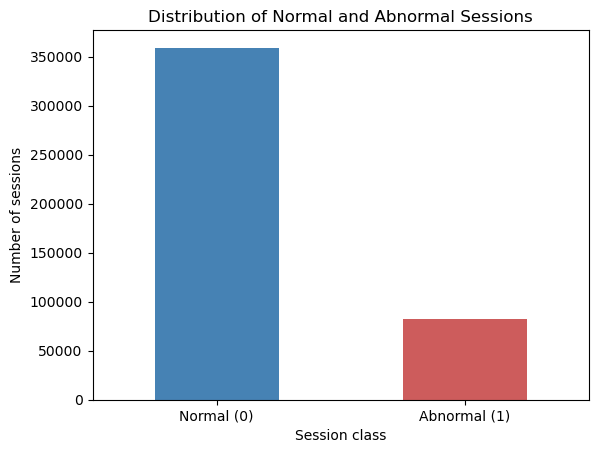

In [19]:

target_counts = df["is_Abnormal"].value_counts().sort_index()

target_counts.plot(
    kind="bar",
    color=["steelblue", "indianred"]
)

plt.title("Distribution of Normal and Abnormal Sessions")
plt.xlabel("Session class")
plt.ylabel("Number of sessions")
plt.xticks(
    ticks=[0, 1],
    labels=["Normal (0)", "Abnormal (1)"],
    rotation=0
)

plt.show()

#### Target distribution

Normal sessions account for 81.42% of observations (359,143), while abnormal sessions account for 18.58% (81,934). The target classes are imbalanced. A classifier that always predicts normal would achieve 81.42% accuracy while detecting no abnormal sessions, so accuracy alone would be insufficient to assess predictive performance.


### 1.6 Numerical and logical consistency

In [20]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
UserID,441077.0,13262.864430,14286.825468,1.000000,2478.000000,8819.000000,19614.000000,56117.000000
Charging Post ID,441077.0,48.829583,25.045206,1.000000,26.000000,51.000000,69.000000,92.000000
Transaction power/kwh,441077.0,16.436574,13.253881,0.000000,5.440000,15.150000,24.740000,117.740000
Electricity cost/Yuan,441077.0,12.158460,10.830214,0.000000,3.340000,10.110000,18.160000,121.160000
Service charge/Yuan,441077.0,7.450791,8.152830,0.000000,1.070000,5.100000,10.990000,101.260000
Transaction Amount/Yuan,441077.0,19.609251,15.958935,0.000000,6.270000,18.440000,29.700000,147.170000
Actual Payment/Yuan,441077.0,18.487883,15.924672,0.000000,4.600000,16.650000,29.370000,147.170000
Temperature(℃),441077.0,19.708336,8.481954,-3.200000,12.700000,21.000000,26.900000,33.600000
Relative Humidity(%),441077.0,75.030351,12.656150,32.000000,67.000000,76.000000,84.000000,99.000000
Precipitation(mm),441077.0,3.510698,10.833238,0.000000,0.000000,0.000000,1.200000,152.100000


In [21]:
# verificar se o número de sessões anormais anteriores não ultrapassa o total de sessões anteriores

session_count_pairs = {
    "post_previous_sessions_1D": "post_previous_abnormal_1D",
    "post_previous_sessions_7D": "post_previous_abnormal_7D",
    "post_previous_sessions_30D": "post_previous_abnormal_30D",
    "user_previous_sessions_30D": "user_previous_abnormal_30D",
    "user_previous_sessions_180D": "user_previous_abnormal_180D",
    "user_previous_sessions_730D": "user_previous_abnormal_730D"
}

for total_column, abnormal_column in session_count_pairs.items():
    invalid_count = (
        df[abnormal_column] > df[total_column]
    ).sum()

    print(abnormal_column, ":", invalid_count)

post_previous_abnormal_1D : 0
post_previous_abnormal_7D : 0
post_previous_abnormal_30D : 0
user_previous_abnormal_30D : 0
user_previous_abnormal_180D : 0
user_previous_abnormal_730D : 0


Previous abnormal-session counts never exceed their corresponding total counts in any of the six checked historical windows.


In [22]:
binary_columns = [
    "post_no_previous_completed_session",
    "post_no_previous_completed_abnormal",
    "is_new_user",
    "user_no_previous_completed_session",
    "user_no_previous_completed_abnormal",
    "is_Abnormal"
]

for column in binary_columns:
    invalid_count = (~df[column].isin([0, 1])).sum()

    print(column, ":", invalid_count)

post_no_previous_completed_session : 0
post_no_previous_completed_abnormal : 0
is_new_user : 0
user_no_previous_completed_session : 0
user_no_previous_completed_abnormal : 0
is_Abnormal : 0


All six checked binary variables contain only 0 and 1, with no missing or invalid values. No corrections are required for these indicators.


In [23]:
zero_energy = df["Transaction power/kwh"] == 0

print("Sessions with zero energy:", zero_energy.sum())
print("Percentage of sessions:", round(zero_energy.mean() * 100, 2))

df.loc[zero_energy, "end_cause"].value_counts()

Sessions with zero energy: 54621
Percentage of sessions: 12.38


end_cause
Other faults of the charging pile                               13650
Vehicle communications failure                                  12896
User stops charging                                              7730
Failure of non-system control loop components and assemblies     5662
Vehicle charging faults                                          5402
Faulty charging connection                                       2687
DC Output Fault                                                  1991
Charging ends normally                                           1328
Power conversion unit failure                                    1257
BMS failure                                                      1153
DC switching device failure                                       680
AC Input Failure                                                   89
System communications failure                                      78
Vehicle Stake Interaction Failure                                  15
AC switchi

There are 54,621 zero-energy sessions, representing approximately 12.38% of the dataset. Under the adopted target definition, 83.42% of these sessions are abnormal. Zero energy is therefore frequently associated with failure-related termination, but also occurs in normal sessions. These observations are retained because zero energy alone is insufficient evidence of a data error.


### 1.7 Predictor distributions

In [24]:
categorical_columns = [
    "Location Information",
    "District Name",
    "tariff_period"
]

for column in categorical_columns:
    print(column)
    print("Number of categories:", df[column].nunique())
    display(df[column].value_counts(dropna=False))

Location Information
Number of categories: 13


Location Information
Bus Station                      60809
Park B                           57294
Shopping Mall                    56605
Expressway Service District C    50187
Government Agency                36551
Wholesale Market                 34491
Technology Park                  28867
Park A                           27845
Tourist Attraction               23659
Financial Industrial Park        18923
Industrial Park                  18370
Expressway Service District A    15075
Expressway Service District B    12401
Name: count, dtype: Int64

District Name
Number of categories: 3


District Name
Tongxiang    220923
Xiuzhou      148705
Nanhu         71449
Name: count, dtype: Int64

tariff_period
Number of categories: 7


tariff_period
peak_13_19        167118
off_peak_11_13     61760
peak_08_11         48977
off_peak_00_08     48633
sharp_19_21        48042
off_peak_22_24     43704
peak_21_22         22843
Name: count, dtype: Int64

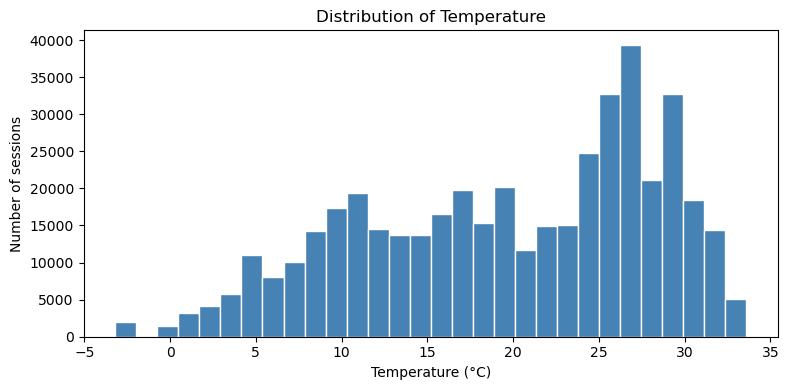

In [25]:
df["Temperature(℃)"].plot(
    kind="hist",
    bins=30,
    figsize=(8, 4),
    color="steelblue",
    edgecolor="white"
)

plt.title("Distribution of Temperature")
plt.xlabel("Temperature (°C)")
plt.ylabel("Number of sessions")
plt.tight_layout()
plt.show()

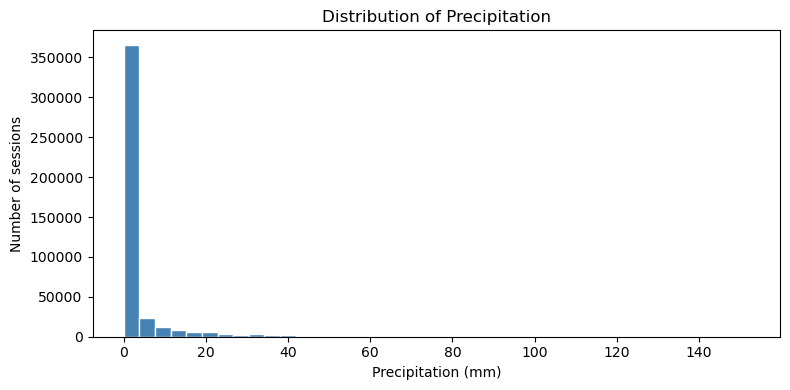

In [26]:
df["Precipitation(mm)"].plot(
    kind="hist",
    bins=40,
    figsize=(8, 4),
    color="steelblue",
    edgecolor="white"
)

plt.title("Distribution of Precipitation")
plt.xlabel("Precipitation (mm)")
plt.ylabel("Number of sessions")
plt.tight_layout()
plt.show()

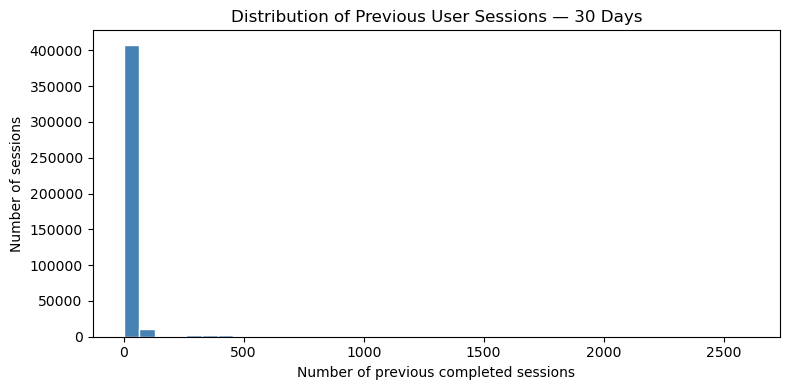

In [27]:
df["user_previous_sessions_30D"].plot(
    kind="hist",
    bins=40,
    figsize=(8, 4),
    color="steelblue",
    edgecolor="white"
)

plt.title("Distribution of Previous User Sessions — 30 Days")
plt.xlabel("Number of previous completed sessions")
plt.ylabel("Number of sessions")
plt.tight_layout()
plt.show()

### 1.8 Context and historical associations

In [28]:
location_summary = (
    df.groupby("Location Information")["is_Abnormal"]
    .agg(["size", "mean"])
    .rename(columns={
        "size": "Session count",
        "mean": "Abnormal rate"
    })
)

location_summary["Abnormal percentage"] = (
    location_summary["Abnormal rate"] * 100
)

location_summary = location_summary.sort_values(
    "Abnormal percentage"
)

location_summary[["Session count", "Abnormal percentage"]]

,Session count,Abnormal percentage
Location Information,,
Industrial Park,18370,7.947741
Park B,57294,8.604740
Technology Park,28867,9.713514
Bus Station,60809,10.037988
Government Agency,36551,12.281470
Financial Industrial Park,18923,19.404957
Park A,27845,20.269348
Expressway Service District B,12401,23.127167
Shopping Mall,56605,25.533080


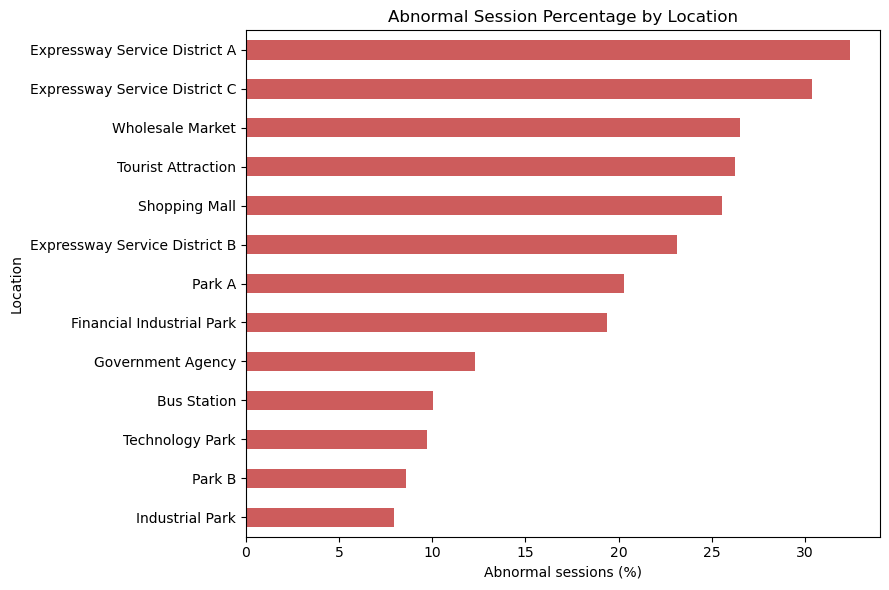

In [29]:
location_summary["Abnormal percentage"].plot(
    kind="barh",
    figsize=(9, 6),
    color="indianred"
)

plt.title("Abnormal Session Percentage by Location")
plt.xlabel("Abnormal sessions (%)")
plt.ylabel("Location")
plt.tight_layout()
plt.show()

,Session count,Abnormal percentage
District Name,,
Tongxiang,220923,14.752199
Nanhu,71449,17.762320
Xiuzhou,148705,24.647456


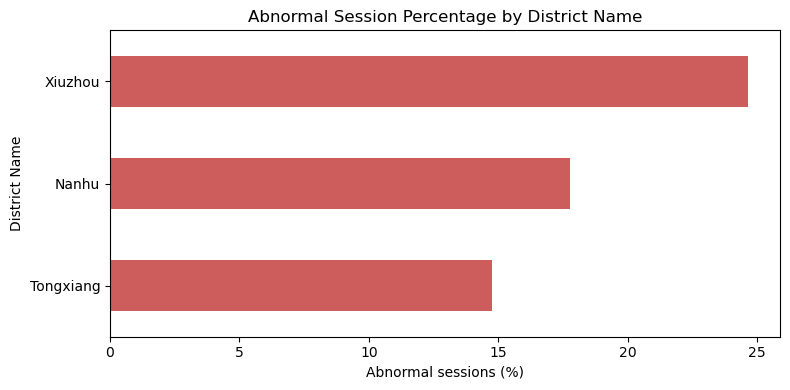

,Session count,Abnormal percentage
tariff_period,,
sharp_19_21,48042,16.741601
peak_21_22,22843,16.819157
peak_08_11,48977,17.536803
off_peak_22_24,43704,18.016658
off_peak_00_08,48633,18.384636
peak_13_19,167118,19.145753
off_peak_11_13,61760,20.480894


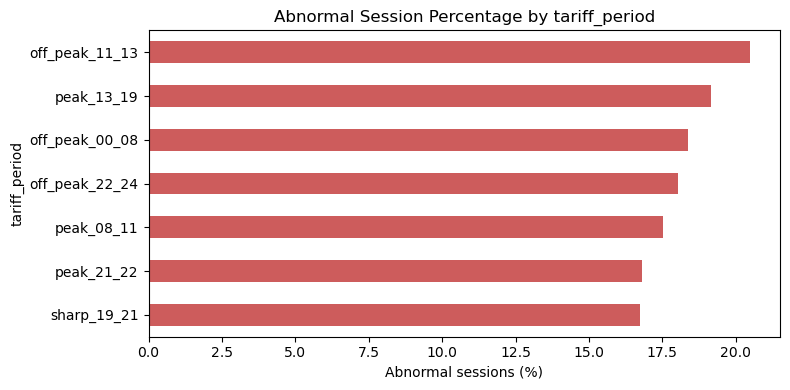

In [30]:
for column in ["District Name", "tariff_period"]:
    summary = (
        df.groupby(column)["is_Abnormal"]
        .agg(["size", "mean"])
        .rename(columns={
            "size": "Session count",
            "mean": "Abnormal rate"
        })
    )

    summary["Abnormal percentage"] = summary["Abnormal rate"] * 100

    summary = summary.sort_values("Abnormal percentage")

    display(summary[["Session count", "Abnormal percentage"]])

    summary["Abnormal percentage"].plot(
        kind="barh",
        figsize=(8, 4),
        color="indianred"
    )

    plt.title(f"Abnormal Session Percentage by {column}")
    plt.xlabel("Abnormal sessions (%)")
    plt.ylabel(column)
    plt.tight_layout()
    plt.show()

Abnormal-session percentages vary across districts, from approximately 14.7% in Tongxiang to 24.7% in Xiuzhou. Differences across tariff periods are smaller, ranging from approximately 16.7% to 20.5%. Both variables remain candidate predictors, although these associations do not establish causality or demonstrate independent predictive value.


In [31]:
new_user_summary = (
    df.groupby("is_new_user")["is_Abnormal"]
    .agg(["size", "mean"])
    .rename(columns={
        "size": "Session count",
        "mean": "Abnormal rate"
    })
)

new_user_summary["Abnormal percentage"] = (
    new_user_summary["Abnormal rate"] * 100
)

new_user_summary[["Session count", "Abnormal percentage"]]

,Session count,Abnormal percentage
is_new_user,,
0,384961,18.287047
1,56116,20.557417


In [32]:
history_columns = [
    "post_previous_abnormal_rate_30D",
    "user_previous_abnormal_rate_730D"
]

history_summary = (
    df.groupby("is_Abnormal")[history_columns]
    .median()
    .T
    .rename(columns={
        0: "Normal median",
        1: "Abnormal median"
    })
)

history_summary

is_Abnormal,Normal median,Abnormal median
post_previous_abnormal_rate_30D,0.121827,0.252174
user_previous_abnormal_rate_730D,0.166667,0.200000


Abnormal sessions have higher median historical abnormal rates than normal sessions. The difference is larger for charging-post history over 30 days (25.22% versus 12.18%) than for user history over 730 days (20.00% versus 16.67%). These associations suggest potentially useful predictive information, but median comparisons alone do not establish predictive performance.


### 1.9 Changes over time

In [33]:
monthly_summary = (
    df.assign(
        Start_month=parsed_dates["Start Time"].dt.to_period("M")
    )
    .groupby("Start_month")["is_Abnormal"]
    .agg(["size", "mean"])
    .rename(columns={
        "size": "Session count",
        "mean": "Abnormal rate"
    })
)

monthly_summary["Abnormal percentage"] = (
    monthly_summary["Abnormal rate"] * 100
)

monthly_summary[["Session count", "Abnormal percentage"]]

,Session count,Abnormal percentage
Start_month,,
2019-12,17,29.411765
2020-01,6217,25.012064
2020-02,1391,26.312006
2020-03,6392,24.780976
2020-04,11136,22.054598
2020-05,15033,19.184461
2020-06,17513,15.993833
2020-07,22032,18.223493
2020-08,25562,20.061028


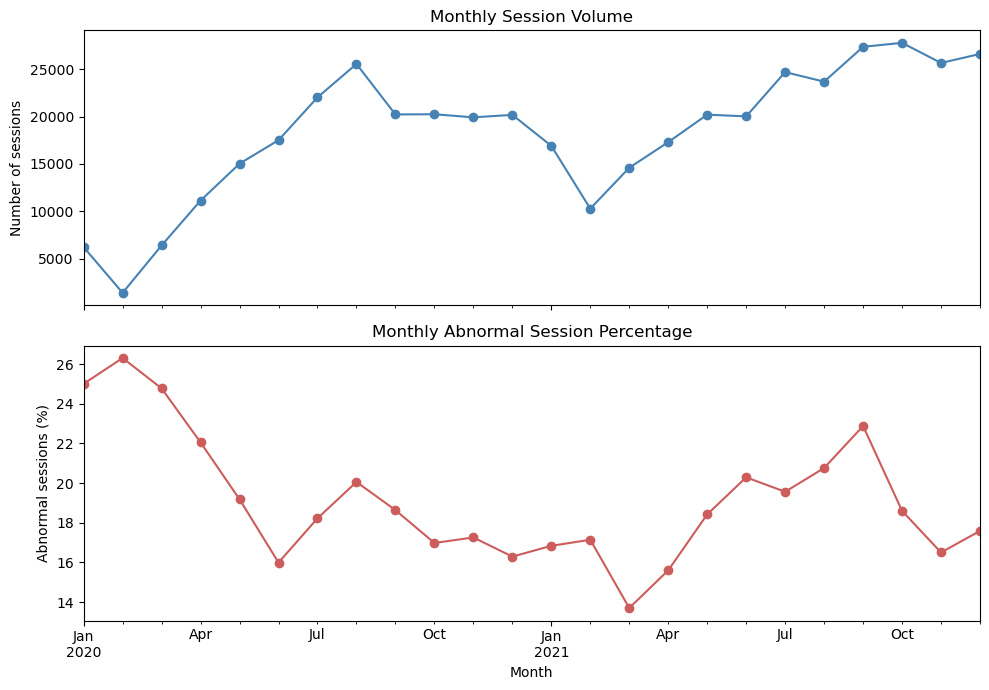

In [34]:
monthly_comparison = monthly_summary.loc["2020-01":].copy()

monthly_comparison.index = (
    monthly_comparison.index.to_timestamp()
)

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

monthly_comparison["Session count"].plot(
    ax=axes[0],
    marker="o",
    color="steelblue"
)

axes[0].set_title("Monthly Session Volume")
axes[0].set_ylabel("Number of sessions")

monthly_comparison["Abnormal percentage"].plot(
    ax=axes[1],
    marker="o",
    color="indianred"
)

axes[1].set_title("Monthly Abnormal Session Percentage")
axes[1].set_ylabel("Abnormal sessions (%)")
axes[1].set_xlabel("Month")

plt.tight_layout()
plt.show()

In [35]:
monthly_activity = (
    df.assign(
        Start_month=parsed_dates["Start Time"].dt.to_period("M")
    )
    .groupby("Start_month")
    .agg(
        Unique_users=("UserID", "nunique"),
        Active_posts=("Charging Post ID", "nunique")
    )
)

monthly_activity = monthly_activity.loc["2020-01":]

monthly_activity

,Unique_users,Active_posts
Start_month,,
2020-01,1963,92
2020-02,516,83
2020-03,1797,92
2020-04,2622,92
2020-05,3153,92
2020-06,3185,91
2020-07,3704,92
2020-08,4733,92
2020-09,4642,92


Monthly unique-user counts range from 516 to 7,519 and generally increase over the observation period. Active charging-post counts are comparatively stable, ranging from 83 to 92. The low session volume in February 2020 coincides with fewer users and active posts. These counts describe recorded activity and do not establish why activity changed or whether inactive posts were unavailable.


In [36]:
monthly_predictors = (
    df.assign(
        Start_month=parsed_dates["Start Time"].dt.to_period("M")
    )
    .groupby("Start_month")
    .agg(
        Median_temperature=("Temperature(℃)", "median"),
        Median_post_abnormal_rate=(
            "post_previous_abnormal_rate_30D", "median"
        ),
        New_user_share=("is_new_user", "mean")
    )
)

monthly_predictors["New_user_percentage"] = (
    monthly_predictors["New_user_share"] * 100
)

monthly_predictors.loc["2020-01":, [
    "Median_temperature",
    "Median_post_abnormal_rate",
    "New_user_percentage"
]]

,Median_temperature,Median_post_abnormal_rate,New_user_percentage
Start_month,,,
2020-01,6.1,0.212766,31.381695
2020-02,10.1,0.190476,23.652049
2020-03,12.6,0.215190,20.854193
2020-04,16.0,0.215602,15.517241
2020-05,23.2,0.176056,12.412692
2020-06,26.1,0.137500,9.678525
2020-07,26.6,0.115942,8.755447
2020-08,31.2,0.127820,10.409984
2020-09,23.0,0.124113,12.703277


Monthly median temperature shows a seasonal pattern, ranging from 5.2°C to 31.2°C. The median historical charging-post abnormal rate also changes over time, ranging from 10.71% to 21.56%. New-user sessions account for 31.38% in January 2020 and a lower, fluctuating proportion thereafter. These changes indicate that session conditions and user composition are not constant over time, supporting the use of temporal validation.


### 1.10 Predictor eligibility and redundancy

In [37]:
post_session_columns = [
    "Transaction power/kwh",
    "Electricity cost/Yuan",
    "Service charge/Yuan",
    "Transaction Amount/Yuan",
    "Actual Payment/Yuan",
    "End Time",
    "Payment time",
    "end_cause"
]

identifier_columns = [
    "UserID",
    "Charging Post ID"
]

excluded_columns = (
    post_session_columns
    + identifier_columns
    + ["Order creation time", "Start Time", "is_Abnormal"]
)

candidate_predictors = [
    column
    for column in df.columns
    if column not in excluded_columns
]

candidate_predictors

['Location Information',
 'District Name',
 'Temperature(℃)',
 'Relative Humidity(%)',
 'Precipitation(mm)',
 'electricity_price',
 'tariff_period',
 'post_previous_sessions_1D',
 'post_previous_abnormal_1D',
 'post_previous_abnormal_rate_1D',
 'post_previous_sessions_7D',
 'post_previous_abnormal_7D',
 'post_previous_abnormal_rate_7D',
 'post_previous_sessions_30D',
 'post_previous_abnormal_30D',
 'post_previous_abnormal_rate_30D',
 'post_hours_since_previous_completed_session',
 'post_no_previous_completed_session',
 'post_hours_since_previous_completed_abnormal',
 'post_no_previous_completed_abnormal',
 'is_new_user',
 'user_previous_sessions_30D',
 'user_previous_abnormal_30D',
 'user_previous_abnormal_rate_30D',
 'user_previous_sessions_180D',
 'user_previous_abnormal_180D',
 'user_previous_abnormal_rate_180D',
 'user_previous_sessions_730D',
 'user_previous_abnormal_730D',
 'user_previous_abnormal_rate_730D',
 'user_days_since_previous_completed_session',
 'user_no_previous_compl

The initial candidate set contains 35 contextual, weather, tariff and historical variables. Post-session outcomes are excluded because they are unavailable at prediction time. Raw identifiers are excluded to reduce memorisation and generalisation risks. Order creation time is excluded because its availability at session start is inconsistent. Calendar features are derived separately from Start Time. No columns are deleted from the original DataFrame.


In [38]:
numeric_predictors = (
    df[candidate_predictors].select_dtypes(include="number")
)

correlation_matrix = numeric_predictors.corr(method="spearman")

high_correlations = []

for i, first_column in enumerate(correlation_matrix.columns):
    for second_column in correlation_matrix.columns[i + 1:]:
        correlation = correlation_matrix.loc[
            first_column, second_column
        ]

        if abs(correlation) > 0.90:
            high_correlations.append({
                "First variable": first_column,
                "Second variable": second_column,
                "Correlation": correlation
            })

high_correlations_table = pd.DataFrame(
    high_correlations,
    columns=["First variable", "Second variable", "Correlation"]
)

high_correlations_table

,First variable,Second variable,Correlation
0,post_previous_sessions_7D,post_previous_sessions_30D,0.906391
1,is_new_user,user_no_previous_completed_session,0.994615
2,user_previous_sessions_30D,user_previous_sessions_180D,0.912261
3,user_previous_sessions_180D,user_previous_sessions_730D,0.980440
4,user_previous_abnormal_180D,user_previous_abnormal_730D,0.962087
5,user_previous_abnormal_rate_180D,user_previous_abnormal_rate_730D,0.959407


Six numerical predictor pairs have Spearman correlations above 0.90. Most involve overlapping historical windows. is_new_user and user_no_previous_completed_session are almost perfectly correlated, although their meanings differ. These findings indicate potential redundancy, but no variables are removed at this stage.


In [39]:
pd.crosstab(
    df["is_new_user"],
    df["user_no_previous_completed_session"]
)

user_no_previous_completed_session,0,1
is_new_user,,
0,384430,531
1,0,56116


The two user-history indicators differ in only 531 observations and are nearly redundant. Both indicators are retained in the current G4 comparison because their meanings differ and no individual removal experiment has been performed. Their near redundancy remains a limitation.


### 1.11 Calendar features and candidate matrix

In [40]:
calendar_features = pd.DataFrame({
    "start_hour": parsed_dates["Start Time"].dt.hour,
    "start_weekday": parsed_dates["Start Time"].dt.dayofweek,
    "start_month": parsed_dates["Start Time"].dt.month,
    "start_is_weekend": (
        parsed_dates["Start Time"].dt.dayofweek >= 5
    ).astype("int64")
})

calendar_features.head()

,start_hour,start_weekday,start_month,start_is_weekend
0,21,1,12,0
1,21,1,12,0
2,22,1,12,0
3,22,1,12,0
4,23,1,12,0


Hour, weekday, month and weekend status are derived from Start Time to represent possible daily, weekly and seasonal patterns. All are available at session start. They are retained in every ablation group as the shared calendar representation. Their separate contributions have not been isolated, and some provide overlapping information.


In [41]:
X_candidates = pd.concat(
    [
        df[candidate_predictors],
        calendar_features
    ],
    axis=1
)

print("Number of rows:", X_candidates.shape[0])
print("Number of candidate predictors:", X_candidates.shape[1])

Number of rows: 441077
Number of candidate predictors: 39


In [42]:
hourly_summary = (
    df.assign(start_hour=calendar_features["start_hour"])
    .groupby("start_hour")["is_Abnormal"]
    .agg(["size", "mean"])
    .rename(columns={
        "size": "Session count",
        "mean": "Abnormal rate"
    })
)

hourly_summary["Abnormal percentage"] = (
    hourly_summary["Abnormal rate"] * 100
)

hourly_summary[["Session count", "Abnormal percentage"]]

,Session count,Abnormal percentage
start_hour,,
0,11381,19.242597
1,7012,19.281232
2,5101,19.623603
3,4548,18.755497
4,3969,19.022424
5,3876,18.317853
6,5670,17.072310
7,7076,15.715093
8,9746,16.632465


Hourly abnormal rates range from 15.72% to 20.67%. This modest association does not establish additional predictive value beyond related variables such as tariff period.


In [43]:
for column in ["start_weekday", "start_is_weekend"]:
    summary = (
        df.assign(**{column: calendar_features[column]})
        .groupby(column)["is_Abnormal"]
        .agg(["size", "mean"])
        .rename(columns={
            "size": "Session count",
            "mean": "Abnormal rate"
        })
    )

    summary["Abnormal percentage"] = summary["Abnormal rate"] * 100

    print(column)
    display(summary[["Session count", "Abnormal percentage"]])

start_weekday


,Session count,Abnormal percentage
start_weekday,,
0,62064,18.211846
1,61465,18.294965
2,62093,18.692928
3,63220,19.166403
4,65562,18.869162
5,64463,18.590509
6,62210,18.175534


start_is_weekend


,Session count,Abnormal percentage
start_is_weekend,,
0,314404,18.652116
1,126673,18.386712


Weekday abnormal rates range from 18.18% to 19.17%; weekend and weekday rates are 18.39% and 18.65%. Differences are small, but this does not rule out interactions with other predictors.


### 1.12 Data preparation decisions

The preparation retains the audited observations, including investigated extremes and zero-energy sessions that were not confirmed as errors. Text categories are cleaned and the target is derived from end_cause. Raw identifiers and post-session information are excluded from the predictors, while historical summaries and calendar features are retained.

Historical time-since variables use constant-zero imputation with their no-history indicators. Correlated predictors are retained and extremes are not capped. Encoding and scaling are fitted separately within each temporal training fold.

#### Historical intervals without prior sessions

Missing values in the four historical time-since variables are replaced with **zero**, retaining each matching no-history indicator. Zero is a placeholder: indicator 1 denotes absence of history, while indicator 0 identifies an observed interval. Median filling would assign an artificial interval where none exists.

This fixed transformation is applied within the modelling pipeline, leaving exploratory data unchanged. It estimates no population statistic. The placeholder can affect distance-sensitive models.

#### Correlated predictors

Overlapping historical windows are strongly correlated. The two user-history flags differ in 531 observations; weekend status is derived from weekday, and tariff period relates to electricity price.

The 39 candidates are retained without an individual redundancy-removal experiment. Both user flags, weekend status, historical windows and tariff representations remain included. Their overlapping information is a limitation of the representation.

#### Evaluation scope

The initial exploratory audit covered the full dataset, including the eventual test period. Subsequent feature, model, hyperparameter and threshold selection used training and temporal-validation data. The final model and threshold were fixed before test evaluation. Prior descriptive exposure limits the independence of that evaluation.

## Task 2 Prediction and Temporal Evaluation

### 2.1 Prediction and operational setting

Each observation represents one charging session. **Abnormal termination is positive (1); normal termination is negative (0).** 
The target is derived from `end_cause`: “Charging ends normally” and “User stops charging” are normal; all other observed causes are abnormal. A voluntary stop does not necessarily indicate a technical fault.

Predictions are made at session start to flag higher-risk sessions for monitoring. An alert does not confirm a fault, charging success, or energy transfer, and does not automatically stop charging.

### 2.2 Error consequences

A false positive flags a normal session and creates unnecessary monitoring and possible alert fatigue. A false negative misses an opportunity to monitor an actually abnormal session. An abnormal label does not establish how much energy was transferred.

We consider false negatives more concerning, while still limiting false alerts. No measured error costs or monitoring-capacity limit are available. F1 balances precision and recall but does not encode this preference. Recall, missed abnormalities and false alerts are reported separately. Higher mean recall resolves an exact tie in mean F1.

### 2.3 Admissible predictors

| Variables | Decision | Reason |
|---|---|---|
| Location and district | Eligible | Known at session start |
| Weather | Eligible under an assumption | Estimates or forecasts available at start, as permitted by the brief |
| electricity_price and tariff_period | Eligible | Applicable at session start |
| Post/user history, no-history flags, is_new_user and concurrent activity | Eligible | Supplied chronological information available at prediction time |
| end_cause | Target construction only | Known at termination |
| Final energy, costs, charges, amounts, payment, End Time and Payment time | Excluded | Unavailable at session start |
| UserID and Charging Post ID | Excluded | Reduce direct identity memorisation and generalisation risks |
| Order creation time | Excluded | Not consistently recorded before session start |
| Start Time | Feature derivation only | Create hour, weekday, month and weekend status; exclude raw timestamp |
| is_Abnormal | Target only | Excluded from input features |

The initial matrix has **35 direct candidates plus four calendar features**. Eligibility does not establish predictive usefulness.

Historical summaries represent previously completed sessions. During sequential prediction, completed validation or test sessions may inform later histories without using their labels to train the model. The supplied histories were not independently reconstructed. Feature-group availability and privacy limitations are discussed in the report. The final notebook section assesses ensemble performance with and without completed user history; new-post performance cannot be estimated because those validation cases are absent.

### 2.4 Evaluation metrics

**F1 = 2 TP / (2 TP + FP + FN)** is the primary metric for comparing feature groups, models and hyperparameter configurations, and for selecting the decision threshold. It is the harmonic mean of precision and recall and assesses the positive abnormal class without allowing the many true negatives to dominate the score.

F1 depends on the decision threshold and prevalence. It does not measure probability calibration or encode a greater cost for false negatives. Precision and F1 are reported as zero when no alerts are predicted.

| Complementary measure | Purpose and limitation |
|---|---|
| Recall = TP / (TP + FN) | Fraction of abnormalities detected; alone does not penalise false alerts |
| Precision = TP / (TP + FP) | Fraction of correct alerts; depends on prevalence and omits missed abnormalities |
| Balanced accuracy = (recall + specificity) / 2 | Gives both classes equal weight |
| Confusion matrix: TP, FP, FN, TN | Counts behind the rates |
| Accuracy = (TP + TN) / N | Supplementary overall correctness; can conceal minority-class failure |

Specificity = TN / (TN + FP). Correct alerts = 1,000 TP/N, false alerts = 1,000 FP/N, missed abnormalities = 1,000 FN/N and total alerts = 1,000(TP+FP)/N per 1,000 sessions. The alert rate is 100(TP+FP)/N percent.

Scores and prevalence are presented per fold, with mean, sample standard deviation and range. Fold scores are not independent because training windows overlap.

### 2.5 Chronological training and test split

In [44]:
# Split sessions chronologically into approximately two thirds training and one third testing. 

sorted_start_times = start_time.sort_values()

split_position = int(len(sorted_start_times) * 2 / 3)
split_date = sorted_start_times.iloc[split_position]

train_mask = start_time < split_date
test_mask = start_time >= split_date

X_train = X_candidates.loc[train_mask].copy()
X_test = X_candidates.loc[test_mask].copy()

y_train = df.loc[train_mask, "is_Abnormal"].copy()
y_test = df.loc[test_mask, "is_Abnormal"].copy()

split_summary = pd.DataFrame({
    "Sessions": [
        len(X_train),
        len(X_test)
    ],
    "Percentage of dataset": [
        len(X_train) / len(df) * 100,
        len(X_test) / len(df) * 100
    ],
    "Normal sessions": [
        (y_train == 0).sum(),
        (y_test == 0).sum()
    ],
    "Abnormal sessions": [
        (y_train == 1).sum(),
        (y_test == 1).sum()
    ]
}, index=["Training", "Final test"])

print("Split date:", split_date)
display(split_summary.round(2))

Split date: 2021-07-12 14:28:34


,Sessions,Percentage of dataset,Normal sessions,Abnormal sessions
Training,294051,66.67,240511,53540
Final test,147026,33.33,118632,28394


In [45]:
print("Split date:", split_date)

print(
    "Training period:",
    start_time.loc[train_mask].min(),
    "to",
    start_time.loc[train_mask].max()
)

print(
    "Test period:",
    start_time.loc[test_mask].min(),
    "to",
    start_time.loc[test_mask].max()
)

Split date: 2021-07-12 14:28:34
Training period: 2019-12-31 21:27:03 to 2021-07-12 14:27:42
Test period: 2021-07-12 14:28:34 to 2021-12-31 23:52:14


In [46]:
# Keep only outcomes available before the final test period begins.
final_fit_mask = (
    train_mask
    & (parsed_dates["End Time"] < split_date)
)

X_final_train = X_candidates.loc[final_fit_mask].copy()
y_final_train = df.loc[final_fit_mask, "is_Abnormal"].copy()

print("Initial training sessions:", train_mask.sum())
print("Training sessions still active at the test boundary:", (
    train_mask & ~final_fit_mask
).sum())
print("Sessions eligible for final fitting:", len(X_final_train))

Initial training sessions: 294051
Training sessions still active at the test boundary: 45
Sessions eligible for final fitting: 294006


#### Partition summary

The timestamp at approximately two thirds of sorted sessions determines the cut: **12 July 2021 at 14:28:34**. Earlier starts enter training; starts at or after the cut enter testing. Equal timestamps stay together, and X/y indices remain aligned.

| Initial partition | Sessions | Abnormal percentage |
|---|---:|---:|
| Training | 294,051 (66.67%) | 18.21% |
| Final test | 147,026 (33.33%) | 19.31% |

Training starts on 31 December 2019 and its latest session starts on 12 July 2021 at 14:27:42. The test period begins on 12 July 2021 at 14:28:34 and ends on 31 December 2021. The chronological split assigns approximately two thirds of sessions to training and one third to testing, preserving prevalence differences.

**Outcome availability:** Excluding 45 training sessions that ended at or after the cutoff leaves **294,006 sessions** for final fitting. `End Time` checks label availability and is never a predictor. Outcomes are assumed available when sessions end.

### 2.6 Expanding window validation

In [47]:
train_times = start_time.loc[X_train.index]
train_end_times = parsed_dates.loc[X_train.index, "End Time"]

validation_periods = [
    ("2020-07-01", "2020-10-01"),
    ("2020-10-01", "2021-01-01"),
    ("2021-01-01", "2021-04-01"),
    ("2021-04-01", "2021-07-01")
]

fold_records = []

for fold_number, (validation_start, validation_end) in enumerate(
    validation_periods,
    start=1
):
    validation_start = pd.Timestamp(validation_start)
    validation_end = pd.Timestamp(validation_end)

    fold_train_mask = (
        (train_times < validation_start)
        & (train_end_times < validation_start)
    )

    fold_validation_mask = (
        (train_times >= validation_start)
        & (train_times < validation_end)
    )

    fold_records.append({
        "Fold": fold_number,
        "Training sessions": fold_train_mask.sum(),
        "Validation sessions": fold_validation_mask.sum(),
        "Training abnormal percentage": (
            y_train.loc[fold_train_mask].mean() * 100
        ),
        "Validation abnormal percentage": (
            y_train.loc[fold_validation_mask].mean() * 100
        )
    })

fold_summary = pd.DataFrame(fold_records)

fold_summary.round(2)

,Fold,Training sessions,Validation sessions,Training abnormal percentage,Validation abnormal percentage
0,1,57661,67825,20.20,19.04
1,2,125487,60364,19.57,16.84
2,3,185849,41797,18.69,15.82
3,4,227658,57542,18.16,18.22


#### Quarterly validation periods

Four complete quarterly validation periods lie within the initial training set:

| Fold | Training session starts before | Validation with exclusive end |
|---|---|---|
| 1 | 1 July 2020 | July–September 2020 |
| 2 | 1 October 2020 | October–December 2020 |
| 3 | 1 January 2021 | January–March 2021 |
| 4 | 1 April 2021 | April–June 2021 |

Four quarterly validation folds use an expanding training window. Training includes only sessions completed before each validation period. Earlier validation sessions may enter later training once completed. July sessions before the final-test cutoff are used only for final refitting.


### 2.7 Preprocessing and selection policy

Each configuration and fold uses a fresh preprocessing and model pipeline fitted on eligible training sessions. Missing historical intervals are zero-imputed with no-history indicators retained. Validation inputs are transformed using the fitted preparation.

Each configuration has one common threshold, selected from 0.01 to 0.99 in steps of 0.01 by maximum unweighted mean F1 across the four temporal folds. Ties within 1e-12 are resolved by higher mean recall, lower sample standard deviation of F1 and then higher threshold. A score at or above the threshold produces an abnormal prediction.

Configurations are compared using their unrounded mean validation F1 at the selected thresholds, followed by the defined recall, variability and configuration-specific tie rules. Threshold 0.50 provides a reference. Validation outcomes support both selection and performance description, so the selected development scores may be optimistic.

#### Aggregation across periods

The primary comparison uses unweighted mean F1 at each configuration's common selected threshold, giving each quarter equal importance. Per-fold results include F1 and prevalence; temporal summaries include sample standard deviation and range. Candidates are evaluated on the same validation records.

Precision, recall and confusion counts use the same selected threshold. Summed confusion counts across non-overlapping validation periods give supplementary pooled precision, recall, F1 and operational rates. Pooled F1 differs from mean fold F1 because the two aggregations weight periods differently.

### 2.8 Reference baselines

In [48]:
baseline_records = []

# Comparar duas referências simples nos mesmos períodos temporais
for fold_number, (validation_start, validation_end) in enumerate(validation_periods, 1):
    validation_start, validation_end = pd.Timestamp(validation_start), pd.Timestamp(validation_end)
    eligible = (train_times < validation_start) & (train_end_times < validation_start)
    validation = (train_times >= validation_start) & (train_times < validation_end)
    target = y_train.loc[validation]
    majority_class = int(y_train.loc[eligible].mode().iloc[0])
    for baseline_name, predicted_class in [("Training majority", majority_class), ("Always abnormal", 1)]:
        prediction = np.full(len(target), predicted_class)
        tn, fp, fn, tp = confusion_matrix(target, prediction, labels=[0, 1]).ravel()
        baseline_records.append({
            "Fold": fold_number, "Baseline": baseline_name, "Predicted class": predicted_class,
            "Abnormal prevalence": target.mean(),
            "F1": f1_score(target, prediction, zero_division=0),
            "Precision": precision_score(target, prediction, zero_division=0),
            "Recall": recall_score(target, prediction, zero_division=0),
            "Accuracy": (tp + tn) / len(target),
            "False alerts / 1000": 1000 * fp / len(target),
            "Missed abnormalities / 1000": 1000 * fn / len(target)
        })
baseline_summary = pd.DataFrame(baseline_records)
display(baseline_summary.round(4))

,Fold,Baseline,Predicted class,Abnormal prevalence,F1,Precision,Recall,Accuracy,False alerts / 1000,Missed abnormalities / 1000
0,1,Training majority,0,0.1904,0.0000,0.0000,0.0,0.8096,0.0000,190.4018
1,1,Always abnormal,1,0.1904,0.3199,0.1904,1.0,0.1904,809.5982,0.0000
2,2,Training majority,0,0.1684,0.0000,0.0000,0.0,0.8316,0.0000,168.4282
3,2,Always abnormal,1,0.1684,0.2883,0.1684,1.0,0.1684,831.5718,0.0000
4,3,Training majority,0,0.1582,0.0000,0.0000,0.0,0.8418,0.0000,158.1692
5,3,Always abnormal,1,0.1582,0.2731,0.1582,1.0,0.1582,841.8308,0.0000
6,4,Training majority,0,0.1822,0.0000,0.0000,0.0,0.8178,0.0000,182.2495
7,4,Always abnormal,1,0.1822,0.3083,0.1822,1.0,0.1822,817.7505,0.0000


#### Baseline interpretation

The majority baseline predicts normal in every fold. Despite high accuracy, it detects no abnormalities and has zero recall and F1.

The always-abnormal baseline detects every abnormal session but flags every normal session too. Its F1 ranges from approximately 0.273 to 0.320, showing that a nonzero F1 alone does not imply useful predictions.

### 2.9 Final evaluation protocol

The evaluation procedure consists of five stages:

1. Configuration comparison across four expanding-window folds, with preparation and models fitted on earlier completed sessions.
2. Selection of one common threshold per configuration by maximum mean fold F1, followed by configuration comparison using the predefined tie rules.
3. Analysis of per-fold performance, variability, precision, recall and operational errors, with pooled metrics reported separately.
4. Final fitting on **294,006 eligible training sessions** after fixing predictors, preparation, model parameters and threshold. The 45 sessions still active at the cutoff are excluded.
5. Evaluation on **147,026 test sessions**, including overall, monthly and history-subgroup results. July is a partial test month.

The initial EDA included the eventual test period. Model and threshold selection subsequently used development data only. The final test results did not lead to changes in the selected solution.

### 2.10 Shared evaluation functions

The same temporal filters, threshold criterion and predictive metrics are used throughout the model comparisons. These functions implement the protocol above; they do not fit a model when defined.

#### Eligible training and validation sessions

In [49]:
def temporal_masks(validation_period):
    start, end = map(pd.Timestamp, validation_period)
    training_mask = (train_times < start) & (train_end_times < start)
    validation_mask = (train_times >= start) & (train_times < end)
    return training_mask, validation_mask

#### Candidate selection and threshold search

In [50]:
def select_best_candidate(results):
    candidates = results.copy()
    for column, maximise in [
        ("Mean F1", True), ("Mean recall", True), ("SD F1", False)
    ]:
        if maximise:
            best_value = candidates[column].max()
        else:
            best_value = candidates[column].min()
        candidates = candidates.loc[
            np.abs(candidates[column] - best_value) <= 1e-12
        ]
    return candidates

def select_common_threshold(fold_predictions, thresholds):
    threshold_records = []

    for threshold in thresholds:
        fold_f1, fold_precision, fold_recall = [], [], []

        for fold in fold_predictions:
            actual = np.asarray(fold["Actual"])
            predicted = np.asarray(fold["Probabilities"]) >= threshold
            tp = np.sum(predicted & (actual == 1))
            fp = np.sum(predicted & (actual == 0))
            fn = np.sum(~predicted & (actual == 1))

            precision = tp / (tp + fp) if tp + fp else 0.0
            recall = tp / (tp + fn) if tp + fn else 0.0
            denominator = 2 * tp + fp + fn
            f1 = 2 * tp / denominator if denominator else 0.0
            fold_f1.append(f1)
            fold_precision.append(precision)
            fold_recall.append(recall)

        threshold_records.append({
            "Threshold": threshold,
            "Mean F1": np.mean(fold_f1),
            "SD F1": np.std(fold_f1, ddof=1),
            "Mean precision": np.mean(fold_precision),
            "Mean recall": np.mean(fold_recall)
        })

    results = pd.DataFrame(threshold_records)
    candidates = select_best_candidate(results)

    best = candidates.sort_values("Threshold", ascending=False).iloc[0]
    return best, results

In [51]:
threshold_grid = np.arange(1, 100) / 100

#### Predictive and operational metrics

In [52]:
def evaluate_alert_policy(actual, probabilities, threshold):
    actual = np.asarray(actual)
    probabilities = np.asarray(probabilities)
    if len(actual) == 0:
        raise ValueError("Cannot evaluate an empty period")
    predicted = probabilities >= threshold
    tn, fp, fn, tp = confusion_matrix(actual, predicted, labels=[0, 1]).ravel()
    return {
        "Threshold": threshold, "Sessions": len(actual),
        "Abnormal prevalence": actual.mean(),
        "Precision": precision_score(actual, predicted, zero_division=0),
        "Recall": recall_score(actual, predicted, zero_division=0),
        "F1": f1_score(actual, predicted, zero_division=0),
        "Balanced accuracy": balanced_accuracy_score(actual, predicted),
        "Accuracy": (tp + tn) / len(actual),
        "TP": int(tp), "FP": int(fp), "FN": int(fn), "TN": int(tn),
        "Alert rate (%)": 100 * (tp + fp) / len(actual),
        "Correct alerts / 1000": 1000 * tp / len(actual),
        "False alerts / 1000": 1000 * fp / len(actual),
        "Missed abnormalities / 1000": 1000 * fn / len(actual)
    }




## Task 3 Feature Groups Individual Models and Ensembles

### 3.1 Feature group comparison

We compare four cumulative feature groups: context and weather; adding tariff information; adding charging-post history; and adding user history.

We use a decision tree with limited complexity as a reference model because it captures nonlinear relationships and interactions, generally requires no feature scaling, and provides interpretable rules. We keep the same model parameters and the evaluation protocol defined in Task 2 across all groups, changing only the input features.

The conclusions apply to this model and validation setting. A lack of improvement does not imply that a feature group is unhelpful for other models.


Groups are compared by mean validation F1 at each group's common threshold selected across all four temporal folds. The comparison evaluates G1–G5 over all four temporal folds. G5 combines context/weather with user history, excluding tariff and charging-post history, to examine whether user history alone explains the improvement. G4 is retained as a shared input for the subsequent classifiers because it performs best with this reference tree across all four folds; this does not establish that it is optimal for every model family.

In [53]:
# Context, calendar and weather features
context_weather_features = [
    "Location Information",
    "District Name",
    "start_hour",
    "start_weekday",
    "start_month",
    "start_is_weekend",
    "Temperature(℃)",
    "Relative Humidity(%)",
    "Precipitation(mm)"
]

# Tariff features
tariff_features = [
    "electricity_price",
    "tariff_period"
]

# Charging-post history features
post_history_features = [
    column for column in X_train.columns
    if column.startswith("post_")
]

# User history and concurrent account activity
user_history_features = [
    column for column in X_train.columns
    if column.startswith("user_") or column == "is_new_user"
]

# Cumulative feature groups
feature_groups = {
    "G1": context_weather_features,

    "G2": context_weather_features + tariff_features,

    "G3": context_weather_features + tariff_features
          + post_history_features,

    "G4": context_weather_features + tariff_features
          + post_history_features + user_history_features,

    "G5": context_weather_features + user_history_features
}

for group_name, features in feature_groups.items():
    print(f"{group_name}: {len(features)} features")

G1: 9 features
G2: 11 features
G3: 24 features
G4: 39 features
G5: 24 features


We limit the decision tree to a maximum depth of 5 and require at least 50 training observations per leaf to constrain model complexity and avoid rules supported by very few sessions. We keep these settings fixed across all feature groups to support a controlled comparison.


#### Reference tree and fold training

In [54]:
def train_group_fold(features, validation_period):
    training_mask, validation_mask = temporal_masks(validation_period)

    categorical_features = (
        X_train[features]
        .select_dtypes(include=["object", "string", "category"])
        .columns.tolist()
    )

    numerical_features = [
        column for column in features
        if column not in categorical_features
    ]

    preparation = ColumnTransformer([
        (
            "categories",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numbers",
            SimpleImputer(strategy="constant", fill_value=0),
            numerical_features
        )
    ])

    model = Pipeline([
        ("preparation", preparation),
        ("tree", DecisionTreeClassifier(
            max_depth=5,
            min_samples_leaf=50,
            random_state=42
        ))
    ])

    model.fit(
        X_train.loc[training_mask, features],
        y_train.loc[training_mask]
    )

    probabilities = model.predict_proba(
        X_train.loc[validation_mask, features]
    )[:, 1]

    actual_classes = y_train.loc[validation_mask]

    return actual_classes, probabilities

#### Four temporal folds for every group

In [55]:
group_predictions = {}

for group_name, features in feature_groups.items():
    group_predictions[group_name] = []

    for fold_number, validation_period in enumerate(
        validation_periods, start=1
    ):
        actual_classes, probabilities = train_group_fold(
            features,
            validation_period
        )

        group_predictions[group_name].append({
            "Fold": fold_number,
            "Actual": actual_classes,
            "Probabilities": probabilities
        })

        print(f"{group_name} — Fold {fold_number}: concluído")

G1 — Fold 1: concluído
G1 — Fold 2: concluído
G1 — Fold 3: concluído
G1 — Fold 4: concluído
G2 — Fold 1: concluído
G2 — Fold 2: concluído
G2 — Fold 3: concluído
G2 — Fold 4: concluído
G3 — Fold 1: concluído
G3 — Fold 2: concluído
G3 — Fold 3: concluído
G3 — Fold 4: concluído
G4 — Fold 1: concluído
G4 — Fold 2: concluído
G4 — Fold 3: concluído
G4 — Fold 4: concluído
G5 — Fold 1: concluído
G5 — Fold 2: concluído
G5 — Fold 3: concluído
G5 — Fold 4: concluído


#### Group thresholds and mean validation results

In [56]:
comparison_records = []
for group_name, fold_predictions in group_predictions.items():
    best, threshold_results = select_common_threshold(fold_predictions, threshold_grid)
    comparison_records.append({"Group": group_name, **best.to_dict()})
group_comparison = pd.DataFrame(comparison_records)
display(group_comparison.round(4))

,Group,Threshold,Mean F1,SD F1,Mean precision,Mean recall
0,G1,0.23,0.3469,0.0352,0.2408,0.7175
1,G2,0.23,0.3452,0.0375,0.2394,0.7216
2,G3,0.29,0.5297,0.0477,0.5995,0.4762
3,G4,0.27,0.5414,0.0406,0.5073,0.5811
4,G5,0.22,0.4252,0.0153,0.4271,0.4247


#### Performance by quarter and stability

In [57]:
fold_records = []

for group_name, fold_predictions in group_predictions.items():
    threshold = group_comparison.loc[
        group_comparison["Group"] == group_name,
        "Threshold"
    ].iloc[0]

    for fold in fold_predictions:
        predicted = (
            fold["Probabilities"] >= threshold
        ).astype(int)

        fold_records.append({
            "Group": group_name,
            "Fold": fold["Fold"],
            "F1": f1_score(
                fold["Actual"],
                predicted,
                zero_division=0
            )
        })

fold_results = pd.DataFrame(fold_records)

f1_by_fold = fold_results.pivot(
    index="Fold",
    columns="Group",
    values="F1"
)

display(f1_by_fold.round(4))

Group,G1,G2,G3,G4,G5
Fold,,,,,
1,0.3435,0.3435,0.5840,0.5889,0.4356
2,0.3601,0.3590,0.5187,0.5281,0.4370
3,0.3003,0.2948,0.4705,0.4933,0.4038
4,0.3837,0.3837,0.5455,0.5553,0.4242


In [58]:
group_stability_summary = fold_results.groupby("Group", sort=False)["F1"].agg(
    **{"Mean F1": "mean", "SD F1": "std", "Minimum F1": "min", "Maximum F1": "max"}
).reset_index().sort_values("Group").reset_index(drop=True)
print("Feature-group F1 stability for the fixed reference tree")
display(group_stability_summary.round(4))
group_stability_summary.to_csv("group_stability_summary.csv", index=False)

Feature-group F1 stability for the fixed reference tree


,Group,Mean F1,SD F1,Minimum F1,Maximum F1
0,G1,0.3469,0.0352,0.3003,0.3837
1,G2,0.3452,0.0375,0.2948,0.3837
2,G3,0.5297,0.0477,0.4705,0.5840
3,G4,0.5414,0.0406,0.4933,0.5889
4,G5,0.4252,0.0153,0.4038,0.4370


#### Feature group conclusions

G4, combining context, weather, tariff, and charging-post and user histories, achieved the highest mean F1 (**0.5414**) and the best performance across all four folds.

Charging-post history provided the largest improvement. Adding user history produced a smaller but consistent gain across all folds. G5 also outperformed G1 in every fold, showing that user history adds predictive value even without charging-post history. Adding tariff information alone did not improve mean F1 in the fixed-tree comparison.

Therefore, **G4 is provisionally selected for the next model comparisons**. These findings apply to the decision tree and temporal validation periods evaluated; they do not establish performance on the final test set.

### 3.2 Individual classification models

We compare three modelling principles using G4 and the same four expanding-window folds.

| Model | Principle | Justification and limitations |
|---|---|---|
| Logistic Regression | Linear | Efficient reference with interpretable coefficients, although correlated histories complicate interpretation. Encoded categories and standardised numerical features are used. Linear log-odds can miss nonlinear effects and interactions. |
| Decision Tree | Tree-based | Captures thresholds and interactions through interpretable rules, without numerical scaling. Depth and minimum leaf size limit complexity; instability and overfitting remain possible. |
| KNN | Instance-based | Tests whether sessions close in the supplied feature representation tend to have similar outcomes, without a linear boundary or Gaussian feature assumptions. Scaling and categorical encoding are required. Correlated histories and mixed feature types may distort Euclidean distances, and neighbour search has a computational cost. |

F1 is the primary comparison metric, with precision, recall and temporal variability reported alongside it. Threshold selection adjusts the alert policy but does not remove training imbalance or encode asymmetric error costs. All preprocessing is fitted on each fold's past training sessions only.

KNN receives a limited six-configuration search over neighbour count and weighting. The tree and logistic regression remain initial configurations, so the resulting comparison has unequal tuning effort and is provisional. No final-test observations are used. Ensemble methods are evaluated separately.

#### 3.2.1 Decision tree reference

The G4 tree and its four validation prediction sets were produced during the feature-group comparison. These results are reused in the individual-model comparison; no additional reference-tree fit is required.

In [59]:
g4_features = feature_groups["G4"]
tree_g4 = group_comparison.loc[group_comparison["Group"] == "G4"].iloc[0]

#### 3.2.2 Logistic regression preparation

In [60]:
logistic_categorical_features = (
    X_train[g4_features]
    .select_dtypes(include=["object", "string", "category"])
    .columns.tolist()
)

logistic_numerical_features = [
    column for column in g4_features
    if column not in logistic_categorical_features
]

# Impute and scale numerical features
logistic_numerical_pipeline = Pipeline([
    ("imputation", SimpleImputer(
        strategy="constant",
        fill_value=0
    )),
    ("scaling", StandardScaler())
])

# Prepare categorical and numerical features separately
logistic_preprocessor = ColumnTransformer([
    ("categories", OneHotEncoder(
        handle_unknown="ignore"
    ), logistic_categorical_features),

    ("numbers", logistic_numerical_pipeline,
     logistic_numerical_features)
])

# Initial configuration, before hyperparameter tuning
model_logistic = Pipeline([
    ("preparation", logistic_preprocessor),
    ("classifier", LogisticRegression(
        C=1.0,
        class_weight=None,
        max_iter=2000,
        random_state=42
    ))
])

#### Logistic regression temporal training

In [61]:
logistic_predictions = []

for fold_number, validation_period in enumerate(
    validation_periods, start=1
):
    training_mask, validation_mask = temporal_masks(validation_period)

    # Create a fresh pipeline for each fold
    fold_model = clone(model_logistic)

    start = perf_counter()

    fold_model.fit(
        X_train.loc[training_mask, g4_features],
        y_train.loc[training_mask]
    )

    training_seconds = perf_counter() - start

    probabilities = fold_model.predict_proba(
        X_train.loc[validation_mask, g4_features]
    )[:, 1]

    logistic_predictions.append({
        "Fold": fold_number,
        "Actual": y_train.loc[validation_mask],
        "Probabilities": probabilities,
        "Training seconds": training_seconds
    })

    print(
        f"Logistic regression — Fold {fold_number}: "
        f"completed ({training_seconds:.1f} seconds)"
    )

Logistic regression — Fold 1: completed (0.3 seconds)
Logistic regression — Fold 2: completed (0.8 seconds)
Logistic regression — Fold 3: completed (0.9 seconds)
Logistic regression — Fold 4: completed (1.2 seconds)


#### Logistic regression threshold

In [62]:
best_logistic, logistic_threshold_results = select_common_threshold(
    logistic_predictions, threshold_grid
)

#### 3.2.3 KNN configuration search

The search compares 5, 15 and 31 neighbours, each with uniform or inverse-distance weights. More neighbours can smooth local variation; distance weights give closer sessions more influence. Euclidean distance, G4 and preprocessing remain fixed, isolating the two configuration choices. Standardisation does not remove correlated information.

Each configuration selects a common threshold from 0.01 to 0.99 across the four folds. Selection uses mean F1, then higher mean recall and lower sample standard deviation of F1. Remaining within-configuration ties favour the higher threshold; remaining between-configuration ties favour uniform weights and then more neighbours. These are deterministic conventions. The same validation records support selection and description, so the results are development estimates.

In [63]:
# Reuse the same training-only preparation as logistic regression
model_knn = Pipeline([
    ("preparation", clone(logistic_preprocessor)),
    ("classifier", KNeighborsClassifier(
        metric="minkowski",
        p=2,
        algorithm="brute",
        n_jobs=2
    ))
])

knn_configurations = [
    {"Neighbours": neighbours, "Weights": weights}
    for neighbours in [5, 15, 31]
    for weights in ["uniform", "distance"]
]

pd.DataFrame(knn_configurations)

,Neighbours,Weights
0,5,uniform
1,5,distance
2,15,uniform
3,15,distance
4,31,uniform
5,31,distance


#### KNN temporal training

In [64]:
knn_tuning_predictions = {}

for configuration in knn_configurations:
    neighbours = configuration["Neighbours"]
    weights = configuration["Weights"]
    configuration_name = f"k={neighbours}, weights={weights}"
    knn_tuning_predictions[configuration_name] = []

    for fold_number, validation_period in enumerate(validation_periods, start=1):
        training_mask, validation_mask = temporal_masks(validation_period)

        fold_model = clone(model_knn).set_params(
            classifier__n_neighbors=neighbours,
            classifier__weights=weights
        )
        print(f"KNN {configuration_name} - Fold {fold_number}: training...", flush=True)
        start = perf_counter()
        fold_model.fit(
            X_train.loc[training_mask, g4_features],
            y_train.loc[training_mask]
        )
        training_seconds = perf_counter() - start

        print(f"Predicting {validation_mask.sum():,} validation sessions...", flush=True)
        start = perf_counter()
        probabilities = fold_model.predict_proba(
            X_train.loc[validation_mask, g4_features]
        )[:, 1]
        prediction_seconds = perf_counter() - start

        knn_tuning_predictions[configuration_name].append({
            "Fold": fold_number,
            "Actual": y_train.loc[validation_mask],
            "Probabilities": probabilities,
            "Training seconds": training_seconds,
            "Prediction seconds": prediction_seconds
        })
        print(
            f"KNN {configuration_name} - Fold {fold_number}: "
            f"training {training_seconds:.1f}s, prediction {prediction_seconds:.1f}s",
            flush=True
        )


KNN k=5, weights=uniform - Fold 1: training...
Predicting 67,825 validation sessions...
KNN k=5, weights=uniform - Fold 1: training 0.2s, prediction 5.3s
KNN k=5, weights=uniform - Fold 2: training...
Predicting 60,364 validation sessions...
KNN k=5, weights=uniform - Fold 2: training 0.3s, prediction 7.3s
KNN k=5, weights=uniform - Fold 3: training...
Predicting 41,797 validation sessions...
KNN k=5, weights=uniform - Fold 3: training 0.4s, prediction 7.5s
KNN k=5, weights=uniform - Fold 4: training...
Predicting 57,542 validation sessions...
KNN k=5, weights=uniform - Fold 4: training 0.4s, prediction 12.7s
KNN k=5, weights=distance - Fold 1: training...
Predicting 67,825 validation sessions...
KNN k=5, weights=distance - Fold 1: training 0.1s, prediction 3.9s
KNN k=5, weights=distance - Fold 2: training...
Predicting 60,364 validation sessions...
KNN k=5, weights=distance - Fold 2: training 0.3s, prediction 7.5s
KNN k=5, weights=distance - Fold 3: training...
Predicting 41,797 valid

#### KNN validation results

In [65]:
knn_tuning_records = []
knn_threshold_results = {}

for configuration in knn_configurations:
    neighbours = configuration["Neighbours"]
    weights = configuration["Weights"]
    name = f"k={neighbours}, weights={weights}"
    fold_predictions = knn_tuning_predictions[name]
    if len(fold_predictions) != len(validation_periods):
        raise ValueError(f"Incomplete temporal folds for {name}")

    best, threshold_results = select_common_threshold(fold_predictions, threshold_grid)
    knn_threshold_results[name] = threshold_results
    knn_tuning_records.append({
        "Configuration": name,
        "Neighbours": neighbours,
        "Weights": weights,
        **best.to_dict(),
        "Training seconds": sum(f["Training seconds"] for f in fold_predictions),
        "Prediction seconds": sum(f["Prediction seconds"] for f in fold_predictions)
    })

knn_tuning_summary = pd.DataFrame(knn_tuning_records)
display(knn_tuning_summary.round(4))

,Configuration,Neighbours,Weights,Threshold,Mean F1,SD F1,Mean precision,Mean recall,Training seconds,Prediction seconds
0,"k=5, weights=uniform",5,uniform,0.40,0.4627,0.0510,0.4364,0.4935,1.2550,32.8667
1,"k=5, weights=distance",5,distance,0.34,0.4628,0.0510,0.4366,0.4933,1.4222,34.1666
2,"k=15, weights=uniform",15,uniform,0.33,0.5001,0.0472,0.5191,0.4826,1.5489,34.5563
3,"k=15, weights=distance",15,distance,0.31,0.5001,0.0472,0.5197,0.4820,1.4879,34.7120
4,"k=31, weights=uniform",31,uniform,0.29,0.5153,0.0462,0.5293,0.5024,1.3934,35.3194
5,"k=31, weights=distance",31,distance,0.28,0.5153,0.0463,0.5310,0.5008,1.7110,36.2532


#### Selected KNN configuration

In [66]:
# Select the KNN configuration using the same primary and tie metrics.
candidates = select_best_candidate(knn_tuning_summary)

candidates = candidates.assign(
    weight_order=candidates["Weights"].map({"uniform": 0, "distance": 1})
)
best_knn_configuration = candidates.sort_values(
    ["weight_order", "Neighbours"], ascending=[True, False]
).iloc[0]

metric_columns = [
    "Threshold", "Mean F1", "SD F1", "Mean precision", "Mean recall"
]
best_knn = best_knn_configuration[metric_columns].copy()
knn_predictions = knn_tuning_predictions[best_knn_configuration["Configuration"]]
selected_knn_model = clone(model_knn).set_params(
    classifier__n_neighbors=int(best_knn_configuration["Neighbours"]),
    classifier__weights=best_knn_configuration["Weights"]
)

### 3.3 Comparison of the three individual models

In [67]:
# Rebuild the comparison so reruns cannot retain old models or duplicate rows.
model_comparison = pd.DataFrame([
    {"Model": "Decision Tree", **tree_g4[metric_columns].to_dict()},
    {"Model": "Logistic Regression", **best_logistic[metric_columns].to_dict()},
    {"Model": "KNN", **best_knn.to_dict()}
])

print("Selected KNN configuration:", best_knn_configuration["Configuration"])
display(model_comparison.round(4))

Selected KNN configuration: k=31, weights=uniform


,Model,Threshold,Mean F1,SD F1,Mean precision,Mean recall
0,Decision Tree,0.27,0.5414,0.0406,0.5073,0.5811
1,Logistic Regression,0.25,0.5357,0.0409,0.5267,0.5462
2,KNN,0.29,0.5153,0.0462,0.5293,0.5024


In [68]:
knn_tuning_summary.to_csv("knn_tuning_summary.csv", index=False)
model_comparison.to_csv("individual_model_comparison.csv", index=False)

### 3.4 Initial ensemble models

Three ensemble principles are evaluated on G4 using the same four expanding-window folds.

| Ensemble | Principle and motivation | Initial configuration and limitations |
|---|---|---|
| Random Forest | Bootstrap samples and random feature subsets diversify trees; averaging can reduce the instability of an individual tree. | 200 trees, depth 12, minimum leaf size 50, square-root feature sampling and 80% bootstrap samples. These fixed starting values allow richer trees while constraining small leaves. Gains cannot be attributed solely to aggregation because the individual-tree complexity differs. |
| Histogram Gradient Boosting | Sequential small trees can capture nonlinear patterns and interactions missed by a linear reference. | 150 iterations, learning rate 0.08, at most 15 leaves and minimum leaf size 50. These are starting values, not tuned optima. Automatic early stopping is disabled to avoid a random internal validation split. |
| Equal-weight Soft Voting | Average probabilities from logistic regression, the depth-5 tree and selected KNN. Different modelling principles may have complementary errors. | Their G4 validation probabilities are averaged with weights 1/3 each, before applying the ensemble threshold. Correlated errors and different calibration may prevent improvement. |

Random forest and boosting use training-only one-hot encoding and numerical zero imputation with no-history flags retained; neither requires numerical standardisation. The voting components retain their own preparation. No resampling or class weights are introduced in these initial ensembles. All three select a separate common threshold using the same validation F1 rule.

These comparisons reuse development data for feature, KNN and threshold choices and are potentially optimistic. The tree and logistic regression remain initial configurations while KNN has received limited tuning; search effort is unequal.

#### Ensemble preparation

In [69]:
def make_tree_ensemble_pipeline(classifier, dense_categories=False):
    categorical_features = (
        X_train[g4_features]
        .select_dtypes(include=["object", "string", "category"])
        .columns.tolist()
    )
    numerical_features = [
        column for column in g4_features
        if column not in categorical_features
    ]
    preparation = ColumnTransformer([
        ("categories", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=not dense_categories
        ), categorical_features),
        ("numbers", SimpleImputer(
            strategy="constant", fill_value=0
        ), numerical_features)
    ])
    return Pipeline([
        ("preparation", preparation),
        ("classifier", classifier)
    ])

#### Initial ensemble training across four periods

Each initial ensemble uses a new pipeline in each temporal fold. This stage evaluates the fixed starting configurations from Task 3; the subsequent Task 4 search evaluates alternative hyperparameters.

In [70]:
def train_temporal_ensemble(model, name):
    predictions = []

    for fold_number, period in enumerate(validation_periods, start=1):
        training_mask, validation_mask = temporal_masks(period)
        fold_model = clone(model)

        with threadpool_limits(limits=2):
            start = perf_counter()
            fold_model.fit(
                X_train.loc[training_mask, g4_features],
                y_train.loc[training_mask]
            )
            training_seconds = perf_counter() - start

            print("Calculating validation probabilities...", flush=True)
            start = perf_counter()
            positive_column = np.flatnonzero(fold_model.classes_ == 1).item()
            probabilities = fold_model.predict_proba(
                X_train.loc[validation_mask, g4_features]
            )[:, positive_column]
            prediction_seconds = perf_counter() - start

        if not np.isfinite(probabilities).all():
            raise ValueError(f"Invalid probabilities for {name}, fold {fold_number}")

        predictions.append({
            "Fold": fold_number,
            "Actual": y_train.loc[validation_mask],
            "Probabilities": probabilities,
            "Training seconds": training_seconds,
            "Prediction seconds": prediction_seconds
        })
        print(
            f"{name} - Fold {fold_number}: training {training_seconds:.1f}s, "
            f"prediction {prediction_seconds:.1f}s", flush=True
        )

    return predictions


#### 3.4.1 Random Forest initial configuration

In [71]:
model_forest = make_tree_ensemble_pipeline(
    RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        min_samples_leaf=50,
        max_features="sqrt",
        bootstrap=True,
        max_samples=0.8,
        class_weight=None,
        random_state=42,
        n_jobs=2
    )
)

In [72]:
forest_predictions = train_temporal_ensemble(
    model_forest,
    "Random Forest"
)

Calculating validation probabilities...
Random Forest - Fold 1: training 11.0s, prediction 0.8s
Calculating validation probabilities...
Random Forest - Fold 2: training 25.6s, prediction 0.7s
Calculating validation probabilities...
Random Forest - Fold 3: training 42.5s, prediction 0.7s
Calculating validation probabilities...
Random Forest - Fold 4: training 55.4s, prediction 0.8s


#### 3.4.2 Histogram Gradient Boosting initial configuration

In [73]:
# Histogram gradient boosting requires a dense feature matrix.
model_boosting = make_tree_ensemble_pipeline(
    HistGradientBoostingClassifier(
        max_iter=150,
        learning_rate=0.08,
        max_leaf_nodes=15,
        min_samples_leaf=50,
        early_stopping=False,
        class_weight=None,
        random_state=42
    ),
    dense_categories=True
)

In [74]:
boosting_predictions = train_temporal_ensemble(
    model_boosting,
    "Histogram Gradient Boosting"
)

Calculating validation probabilities...
Histogram Gradient Boosting - Fold 1: training 2.7s, prediction 1.0s
Calculating validation probabilities...
Histogram Gradient Boosting - Fold 2: training 5.1s, prediction 1.0s
Calculating validation probabilities...
Histogram Gradient Boosting - Fold 3: training 6.9s, prediction 0.5s
Calculating validation probabilities...
Histogram Gradient Boosting - Fold 4: training 9.3s, prediction 0.8s


#### 3.4.3 Equal weight soft voting

In [75]:
# Reuse predictions from the same G4 sessions; no component retraining here.
voting_components = {
    "Logistic Regression": logistic_predictions,
    "Decision Tree": group_predictions["G4"],
    "KNN": knn_predictions
}

for name, predictions in voting_components.items():
    if len(predictions) != len(validation_periods):
        raise ValueError(f"Incomplete temporal folds for {name}")

soft_voting_predictions = []

for fold_index in range(len(validation_periods)):
    reference = logistic_predictions[fold_index]
    actual = reference["Actual"]
    fold_number = reference["Fold"]
    component_probabilities = []

    for name, predictions in voting_components.items():
        fold = predictions[fold_index]
        if fold["Fold"] != fold_number or not fold["Actual"].equals(actual):
            raise ValueError(f"Validation sessions or targets do not match for {name}")
        probabilities = np.asarray(fold["Probabilities"])
        if probabilities.shape != (len(actual),):
            raise ValueError(f"Invalid probability shape for {name}")
        if not np.isfinite(probabilities).all() or np.any(
            (probabilities < 0) | (probabilities > 1)
        ):
            raise ValueError(f"Invalid probabilities for {name}")
        component_probabilities.append(probabilities)

    start = perf_counter()
    voting_probabilities = np.mean(component_probabilities, axis=0)
    combination_seconds = perf_counter() - start
    soft_voting_predictions.append({
        "Fold": fold_number,
        "Actual": actual.copy(),
        "Probabilities": voting_probabilities,
        "Combination seconds": combination_seconds
    })

print("Soft voting combines probabilities from all three models with equal weights.")


Soft voting combines probabilities from all three models with equal weights.


#### Ensemble thresholds and results

In [76]:
ensemble_predictions = {
    "Random Forest": forest_predictions,
    "Histogram Gradient Boosting": boosting_predictions,
    "Soft Voting LR + Tree + KNN": soft_voting_predictions
}
ensemble_records = []
ensemble_fold_records = []
ensemble_threshold_results = {}

for name, predictions in ensemble_predictions.items():
    if len(predictions) != len(validation_periods):
        raise ValueError(f"Incomplete temporal folds for {name}")
    best, threshold_results = select_common_threshold(predictions, threshold_grid)
    ensemble_threshold_results[name] = threshold_results
    ensemble_records.append({"Model": name, **best.to_dict()})

    for fold in predictions:
        metrics = evaluate_alert_policy(
            fold["Actual"], fold["Probabilities"], best["Threshold"]
        )
        record = {"Model": name, "Fold": fold["Fold"]}
        for column in [
            "Threshold", "F1", "Precision", "Recall", "TP", "FP", "FN", "TN",
            "False alerts / 1000", "Missed abnormalities / 1000"
        ]:
            record[column] = metrics[column]
        ensemble_fold_records.append(record)


ensemble_comparison = pd.DataFrame(ensemble_records)
ensemble_fold_results = pd.DataFrame(ensemble_fold_records)



### 3.5 Comparison of all six models

In [77]:
# Keep the individual table intact; rebuild the joint table on every execution.
all_model_comparison = pd.concat([
    model_comparison.assign(Type="Individual"),
    ensemble_comparison.assign(Type="Ensemble")
], ignore_index=True)

print("Mean validation metrics at each model's common selected threshold:")
display(all_model_comparison[["Model", "Type"] + metric_columns].round(4))


Mean validation metrics at each model's common selected threshold:


,Model,Type,Threshold,Mean F1,SD F1,Mean precision,Mean recall
0,Decision Tree,Individual,0.27,0.5414,0.0406,0.5073,0.5811
1,Logistic Regression,Individual,0.25,0.5357,0.0409,0.5267,0.5462
2,KNN,Individual,0.29,0.5153,0.0462,0.5293,0.5024
3,Random Forest,Ensemble,0.26,0.5575,0.0353,0.5437,0.5734
4,Histogram Gradient Boosting,Ensemble,0.29,0.5601,0.0400,0.5876,0.5363
5,Soft Voting LR + Tree + KNN,Ensemble,0.26,0.5474,0.0416,0.5545,0.5411


In [78]:
print("Ensemble F1 by temporal fold:")
display(ensemble_fold_results.pivot(
    index="Fold", columns="Model", values="F1"
).round(4))


Ensemble F1 by temporal fold:


Model,Histogram Gradient Boosting,Random Forest,Soft Voting LR + Tree + KNN
Fold,,,
1,0.6056,0.5962,0.5929
2,0.5491,0.5502,0.5357
3,0.5110,0.5127,0.4957
4,0.5747,0.5708,0.5652


In [79]:
print("Training and prediction times for the newly fitted ensembles:")
display(pd.DataFrame([
    {
        "Model": name,
        "Training seconds": sum(f["Training seconds"] for f in predictions),
        "Prediction seconds": sum(f["Prediction seconds"] for f in predictions)
    }
    for name, predictions in [
        ("Random Forest", forest_predictions),
        ("Histogram Gradient Boosting", boosting_predictions)
    ]
]).round(2))
print("Voting reuses component predictions. Its averaging time excludes component costs.")



Training and prediction times for the newly fitted ensembles:


,Model,Training seconds,Prediction seconds
0,Random Forest,134.41,3.06
1,Histogram Gradient Boosting,24.01,3.37


Voting reuses component predictions. Its averaging time excludes component costs.


In [80]:
ensemble_comparison.to_csv("ensemble_comparison.csv", index=False)
ensemble_fold_results.to_csv("ensemble_fold_results.csv", index=False)
all_model_comparison.to_csv("all_model_comparison.csv", index=False)

### 3.6 Detailed temporal and operational evaluation

The following tables reuse validation predictions at the common thresholds already selected for each model. They report individual-model performance by fold and aggregate confusion counts for all six models. Pooled metrics weight sessions equally and can differ from the unweighted mean of fold metrics used for model selection. These are development results after feature, configuration and threshold selection, rather than an independent final-test estimate.


#### Individual model results by fold

In [81]:
evaluation_predictions = {
    "Decision Tree": group_predictions["G4"],
    "Logistic Regression": logistic_predictions,
    "KNN": knn_predictions,
    **ensemble_predictions
}
evaluation_thresholds = all_model_comparison.set_index("Model")["Threshold"]
diagnostic_records = []

for name, predictions in evaluation_predictions.items():
    threshold = float(evaluation_thresholds.loc[name])
    if len(predictions) != len(validation_periods):
        raise ValueError(f"Incomplete temporal folds for {name}")
    for fold in predictions:
        metrics = evaluate_alert_policy(
            fold["Actual"], fold["Probabilities"], threshold
        )
        record = {"Model": name, "Fold": fold["Fold"]}
        for column in [
            "Threshold", "Sessions", "Abnormal prevalence", "Accuracy", "F1",
            "Precision", "Recall", "Balanced accuracy", "TP", "FP", "FN", "TN",
            "Correct alerts / 1000", "Alert rate (%)"
        ]:
            record[column] = metrics[column]
        record["Alerts / 1000"] = 1000 * (metrics["TP"] + metrics["FP"]) / metrics["Sessions"]
        record["False alerts / 1000"] = metrics["False alerts / 1000"]
        record["Missed abnormalities / 1000"] = metrics["Missed abnormalities / 1000"]
        diagnostic_records.append(record)

model_fold_diagnostics = pd.DataFrame(diagnostic_records)
individual_fold_diagnostics = model_fold_diagnostics.loc[
    model_fold_diagnostics["Model"].isin(model_comparison["Model"])
].copy()
print("Individual classifiers: metrics and confusion counts by temporal fold")
display(individual_fold_diagnostics[[
    "Model", "Fold", "Sessions", "Abnormal prevalence", "F1", "Precision", "Recall",
    "TP", "FP", "FN", "TN"
]].round(4))



Individual classifiers: metrics and confusion counts by temporal fold


,Model,Fold,Sessions,Abnormal prevalence,F1,Precision,Recall,TP,FP,FN,TN
0,Decision Tree,1,67825,0.1904,0.5889,0.5719,0.6069,7838,5867,5076,49044
1,Decision Tree,2,60364,0.1684,0.5281,0.4882,0.5750,5846,6128,4321,44069
2,Decision Tree,3,41797,0.1582,0.4933,0.4578,0.5349,3536,4188,3075,30998
3,Decision Tree,4,57542,0.1822,0.5553,0.5113,0.6077,6373,6092,4114,40963
4,Logistic Regression,1,67825,0.1904,0.5791,0.5605,0.5990,7735,6064,5179,48847
5,Logistic Regression,2,60364,0.1684,0.5185,0.5408,0.4979,5062,4298,5105,45899
6,Logistic Regression,3,41797,0.1582,0.4873,0.4665,0.5101,3372,3857,3239,31329
7,Logistic Regression,4,57542,0.1822,0.5577,0.5389,0.5780,6061,5186,4426,41869
8,KNN,1,67825,0.1904,0.5626,0.5633,0.5619,7257,5626,5657,49285
9,KNN,2,60364,0.1684,0.5066,0.5303,0.4848,4929,4365,5238,45832


#### Pooled validation counts and operational consequences

In [82]:
pooled_records = []
for name, rows in model_fold_diagnostics.groupby("Model", sort=False):
    counts = rows[["TP", "FP", "FN", "TN"]].sum()
    tp, fp, fn, tn = (int(counts[key]) for key in ["TP", "FP", "FN", "TN"])
    sessions = tp + fp + fn + tn
    pooled_records.append({
        "Model": name, "Threshold": float(evaluation_thresholds.loc[name]),
        "Sessions": sessions, "TP": tp, "FP": fp, "FN": fn, "TN": tn,
        "Abnormal prevalence": (tp + fn) / sessions,
        "Accuracy": (tp + tn) / sessions,
        "Balanced accuracy": (tp / (tp + fn) + tn / (tn + fp)) / 2,
        "Correct alerts / 1000": 1000 * tp / sessions,
        "Alert rate (%)": 100 * (tp + fp) / sessions,
        "Pooled F1": 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0,
        "Pooled precision": tp / (tp + fp) if tp + fp else 0,
        "Pooled recall": tp / (tp + fn) if tp + fn else 0,
        "False alerts / 1000": 1000 * fp / sessions,
        "Missed abnormalities / 1000": 1000 * fn / sessions,
        "Alerts / 1000": 1000 * (tp + fp) / sessions
    })
pooled_model_comparison = pd.DataFrame(pooled_records)
print("Pooled validation errors and operational rates; these are not mean-fold metrics")
display(pooled_model_comparison.round(4))
model_fold_diagnostics.to_csv("model_fold_diagnostics.csv", index=False)
pooled_model_comparison.to_csv("pooled_model_comparison.csv", index=False)



Pooled validation errors and operational rates; these are not mean-fold metrics


,Model,Threshold,Sessions,TP,FP,FN,TN,Abnormal prevalence,Accuracy,Balanced accuracy,Correct alerts / 1000,Alert rate (%),Pooled F1,Pooled precision,Pooled recall,False alerts / 1000,Missed abnormalities / 1000,Alerts / 1000
0,Decision Tree,0.27,227528,23593,22275,16586,165074,0.1766,0.8292,0.7342,103.6927,20.1593,0.5484,0.5144,0.5872,97.9000,72.8965,201.5928
1,Logistic Regression,0.25,227528,22230,19405,17949,167944,0.1766,0.8358,0.7248,97.7023,18.2988,0.5434,0.5339,0.5533,85.2862,78.8870,182.9885
2,KNN,0.29,227528,20599,17747,19580,169602,0.1766,0.8359,0.7090,90.5339,16.8533,0.5246,0.5372,0.5127,77.9992,86.0553,168.5331
3,Random Forest,0.26,227528,23471,19410,16708,167939,0.1766,0.8413,0.7403,103.1565,18.8465,0.5652,0.5474,0.5842,85.3082,73.4327,188.4647
4,Histogram Gradient Boosting,0.29,227528,21978,15132,18201,172217,0.1766,0.8535,0.7331,96.5947,16.3101,0.5687,0.5922,0.5470,66.5061,79.9946,163.1008
5,Soft Voting LR + Tree + KNN,0.26,227528,22136,17322,18043,170027,0.1766,0.8446,0.7292,97.2891,17.3420,0.5559,0.5610,0.5509,76.1313,79.3001,173.4204


#### Model stability across periods

In [83]:
# Keep temporal variability separate from metrics recomputed on pooled counts.
model_stability_summary = model_fold_diagnostics.groupby("Model", sort=False).agg(
    **{
        "Mean F1": ("F1", "mean"),
        "SD F1": ("F1", "std"),
        "Minimum F1": ("F1", "min"),
        "Maximum F1": ("F1", "max"),
        "Mean precision": ("Precision", "mean"),
        "Mean recall": ("Recall", "mean"),
        "Mean balanced accuracy": ("Balanced accuracy", "mean"),
        "Mean accuracy": ("Accuracy", "mean")
    }
).reset_index()
print("Temporal stability and supplementary mean metrics across four folds")
display(model_stability_summary.round(4))
print("Validation size and prevalence by fold (identical for every model)")
display(model_fold_diagnostics.loc[
    model_fold_diagnostics["Model"] == "Decision Tree",
    ["Fold", "Sessions", "Abnormal prevalence"]
].round(4))
model_stability_summary.to_csv("model_stability_summary.csv", index=False)



Temporal stability and supplementary mean metrics across four folds


,Model,Mean F1,SD F1,Minimum F1,Maximum F1,Mean precision,Mean recall,Mean balanced accuracy,Mean accuracy
0,Decision Tree,0.5414,0.0406,0.4933,0.5889,0.5073,0.5811,0.7309,0.8286
1,Logistic Regression,0.5357,0.0409,0.4873,0.5791,0.5267,0.5462,0.7211,0.8354
2,KNN,0.5153,0.0462,0.4552,0.5626,0.5293,0.5024,0.7041,0.8360
3,Random Forest,0.5575,0.0353,0.5127,0.5962,0.5437,0.5734,0.7356,0.8419
4,Histogram Gradient Boosting,0.5601,0.0400,0.5110,0.6056,0.5876,0.5363,0.7283,0.8539
5,Soft Voting LR + Tree + KNN,0.5474,0.0416,0.4957,0.5929,0.5545,0.5411,0.7246,0.8447


Validation size and prevalence by fold (identical for every model)


,Fold,Sessions,Abnormal prevalence
0,1,67825,0.1904
1,2,60364,0.1684
2,3,41797,0.1582
3,4,57542,0.1822


### 3.7 Performance with limited history

We assess the ensembles separately for sessions with and without completed user history and for sessions without completed charging-post history. The supplied history flags are matched by original row index. Each model retains its previously selected threshold; no subgroup-specific tuning is performed. Empty subgroups have undefined metrics (NaN), rather than zero performance. Differences are descriptive: subgroup composition and prevalence can differ, so this comparison does not establish causality or fairness.


In [84]:
history_records = []
for name, predictions in ensemble_predictions.items():
    threshold = float(evaluation_thresholds.loc[name])
    actual_series = pd.concat([fold["Actual"] for fold in predictions])
    if not actual_series.index.is_unique:
        raise ValueError("Validation sessions must not be counted twice")
    if not actual_series.equals(y_train.loc[actual_series.index]):
        raise ValueError("Validation targets are not aligned")
    actual = actual_series.to_numpy()
    probabilities = np.concatenate([fold["Probabilities"] for fold in predictions])
    predicted = probabilities >= threshold
    history_flags = df.loc[actual_series.index, [
        "user_no_previous_completed_session", "post_no_previous_completed_session"
    ]]
    subgroups = {
        "No completed user history": history_flags["user_no_previous_completed_session"].to_numpy() == 1,
        "Has completed user history": history_flags["user_no_previous_completed_session"].to_numpy() == 0,
        "No completed post history": history_flags["post_no_previous_completed_session"].to_numpy() == 1
    }
    for subgroup, mask in subgroups.items():
        actual_subset, predicted_subset = actual[mask], predicted[mask]
        sessions = len(actual_subset)
        if sessions:
            tn, fp, fn, tp = confusion_matrix(
                actual_subset, predicted_subset, labels=[0, 1]
            ).ravel()
        else:
            tn, fp, fn, tp = 0, 0, 0, 0
        history_records.append({
            "Model": name, "Subgroup": subgroup, "Sessions": sessions,
            "Abnormal prevalence": actual_subset.mean() if sessions else np.nan,
            "TP": tp, "FP": fp, "FN": fn, "TN": tn,
            "F1": 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else np.nan,
            "Recall": tp / (tp + fn) if tp + fn else np.nan
        })
ensemble_history_diagnostics = pd.DataFrame(history_records)
display(ensemble_history_diagnostics.round(4))
ensemble_history_diagnostics.to_csv("ensemble_history_diagnostics.csv", index=False)

,Model,Subgroup,Sessions,Abnormal prevalence,TP,FP,FN,TN,F1,Recall
0,Random Forest,No completed user history,27474,0.2075,2059,1580,3641,20194,0.4409,0.3612
1,Random Forest,Has completed user history,200054,0.1723,21412,17830,13067,147745,0.5809,0.6210
2,Random Forest,No completed post history,0,NaN,0,0,0,0,NaN,NaN
3,Histogram Gradient Boosting,No completed user history,27474,0.2075,1813,936,3887,20838,0.4292,0.3181
4,Histogram Gradient Boosting,Has completed user history,200054,0.1723,20165,14196,14314,151379,0.5859,0.5848
5,Histogram Gradient Boosting,No completed post history,0,NaN,0,0,0,0,NaN,NaN
6,Soft Voting LR + Tree + KNN,No completed user history,27474,0.2075,2064,1654,3636,20120,0.4383,0.3621
7,Soft Voting LR + Tree + KNN,Has completed user history,200054,0.1723,20072,15668,14407,149907,0.5717,0.5822
8,Soft Voting LR + Tree + KNN,No completed post history,0,NaN,0,0,0,0,NaN,NaN


The ensembles detect abnormalities less effectively for sessions without completed user history. There are no validation sessions without completed charging-post history, so performance for that subgroup cannot be estimated. This limitation matters when considering deployment to new users or newly installed charging posts.

Histogram Gradient Boosting has the highest mean validation F1, but its advantage over Random Forest is small and is not consistent across every fold. At their selected thresholds, boosting produces about **18.8 fewer false alerts per 1,000 sessions**, while missing about **6.6 more abnormalities per 1,000 sessions** than Random Forest. Model choice therefore also depends on the operational balance between false alerts and missed abnormalities.


## Task 4 Model Optimisation and Final Evaluation

### 4.1 Candidate models

We select **Random Forest** and **Histogram Gradient Boosting** for optimisation because they achieved the highest mean validation F1 in Task 3 (0.5575 and 0.5601, respectively), with both improving upon the reference decision tree in all four folds. Selecting promising candidates from development results follows the project brief.

Random Forest offers higher mean recall (0.5734) and lower F1 variability (SD 0.0353), making it relevant when missed abnormalities are a concern. Histogram Gradient Boosting provides higher mean precision (0.5876), the highest mean F1, and lower measured computational cost. Both can capture nonlinear relationships and interactions between context and historical predictors, while representing different ensemble principles.

Optimising these two models keeps the search focused and computationally manageable. Their small initial F1 difference does not establish a definitive winner. We retain **G4**, the **four expanding-window folds** and **mean validation F1** as the primary selection criterion, comparing improvements and temporal stability against the initial configurations. Hyperparameters and thresholds are selected using development data only, before final test evaluation.

### 4.2 Search procedure

We perform a small exhaustive grid search on G4 using the four expanding-window folds from Task 2. Boosting varies learning rate, maximum leaf nodes and minimum leaf size (eight combinations). Forest varies maximum depth, minimum leaf size and feature sampling (eight combinations). These parameters control update size, tree flexibility, support for local rules and diversity among trees. Restricting the grids keeps the computational budget manageable; it does not establish a global optimum.

The original configuration is retained as a candidate for each family. It is already in the forest grid; the original boosting learning rate of 0.08 is evaluated alongside the eight new combinations. Its existing fold predictions are reused. All other parameters, G4, preparation and fold boundaries remain fixed. Automatic boosting early stopping remains disabled.

For each configuration, one common threshold from 0.01 to 0.99 maximises unweighted mean validation F1. Ties follow the existing recall and F1 variability rules; remaining configuration ties prefer the original configuration, then the predefined grid order. Fresh preprocessing and models are fitted only on sessions started and completed before each validation boundary. Predictions from each configuration are kept in memory for threshold selection and comparison within the same execution.

These validation outcomes support both selection and comparison, so the selected results can be optimistic. We compare changes and their consistency across folds without claiming statistical significance.


#### Validation of fold predictions


In [85]:
def validate_search_fold(fold, number, expected_targets):
    actual = expected_targets[number - 1]
    probabilities = np.asarray(fold["Probabilities"])
    if fold["Fold"] != number or not fold["Actual"].equals(actual):
        raise ValueError("Validation fold indices or targets differ")
    if probabilities.shape != (len(actual),) or not np.isfinite(probabilities).all():
        raise ValueError("Invalid validation probability array")
    if np.any((probabilities < 0) | (probabilities > 1)):
        raise ValueError("Validation probabilities are outside [0, 1]")


#### Training one candidate configuration in one fold

In [86]:
def train_configuration_fold(base_model, parameters, model_name, configuration, number):
    training_mask, validation_mask = temporal_masks(
        validation_periods[number - 1]
    )
    fold_model = clone(base_model).set_params(**{
        f"classifier__{name}": value for name, value in parameters.items()
    })
    print(f"{model_name} | {configuration} | Fold {number}: "
          f"training on {training_mask.sum():,} sessions", flush=True)
    with threadpool_limits(limits=2):
        begin = perf_counter()
        fold_model.fit(X_train.loc[training_mask, g4_features],
                       y_train.loc[training_mask])
        training_seconds = perf_counter() - begin
        begin = perf_counter()
        positive_column = np.flatnonzero(fold_model.classes_ == 1).item()
        probabilities = fold_model.predict_proba(
            X_train.loc[validation_mask, g4_features]
        )[:, positive_column]
        prediction_seconds = perf_counter() - begin
    fold = {
        "Fold": number,
        "Actual": y_train.loc[validation_mask],
        "Probabilities": probabilities,
        "Training seconds": training_seconds,
        "Prediction seconds": prediction_seconds
    }
    return fold


#### Summary of one configuration

In [87]:
def summarise_search_configuration(model_name, configuration, parameters, folds, initial):
    best_threshold, curve = select_common_threshold(folds, threshold_grid)
    record = {
        "Model": model_name, "Configuration": configuration,
        **parameters, **best_threshold.to_dict(),
        "Training seconds": sum(f["Training seconds"] for f in folds),
        "Prediction seconds": sum(f["Prediction seconds"] for f in folds),
        "Source": "Reused Task 3 predictions" if initial else "Task 4 fits"
    }
    return record, curve


#### Search coordination

In [88]:
def run_temporal_search(base_model, configurations, model_name,
                        initial_predictions):
    parameter_names = list(configurations[0])
    initial_parameters = {
        name: base_model.get_params()[f"classifier__{name}"]
        for name in parameter_names
    }
    candidates = [initial_parameters] + [
        values for values in configurations if values != initial_parameters
    ]
    expected_targets = []
    for start, end in validation_periods:
        start, end = pd.Timestamp(start), pd.Timestamp(end)
        mask = (train_times >= start) & (train_times < end)
        expected_targets.append(y_train.loc[mask])

    records = []
    threshold_results = {}
    configuration_predictions = {}
    for index, parameters in enumerate(candidates):
        configuration = "Initial" if index == 0 else f"Grid {index:02d}"
        if index == 0:
            folds = initial_predictions
            if len(folds) != len(validation_periods):
                raise ValueError("Initial predictions must contain all temporal folds")
        else:
            folds = []
            for number in range(1, len(validation_periods) + 1):
                fold = train_configuration_fold(
                    base_model, parameters, model_name, configuration, number
                )
                folds.append(fold)
                print(f"Completed: training {fold['Training seconds']:.1f}s, "
                      f"prediction {fold['Prediction seconds']:.1f}s", flush=True)

        for number, fold in enumerate(folds, 1):
            validate_search_fold(fold, number, expected_targets)
        configuration_predictions[configuration] = folds
        record, curve = summarise_search_configuration(
            model_name, configuration, parameters, folds, index == 0
        )
        records.append(record)
        threshold_results[configuration] = curve
        print(f"{model_name} | {configuration}: mean F1 "
              f"{record['Mean F1']:.4f}, "
              f"threshold {record['Threshold']:.2f}", flush=True)

    results = pd.DataFrame(records)
    best = select_best_candidate(results).iloc[0].copy()
    selected_model = clone(base_model).set_params(**{
        f"classifier__{name}": best[name] for name in parameter_names
    })
    return {
        "Results": results, "Best": best,
        "Predictions": configuration_predictions[best["Configuration"]],
        "Threshold results": threshold_results, "Model": selected_model
    }


### 4.3 Histogram Gradient Boosting search

In [89]:
boosting_search_space = {
    "learning_rate": [0.05, 0.10],
    "max_leaf_nodes": [15, 31],
    "min_samples_leaf": [50, 100]
}
boosting_configurations = list(ParameterGrid(boosting_search_space))
print("New boosting configurations:", len(boosting_configurations))
display(pd.DataFrame(boosting_configurations))


New boosting configurations: 8


,learning_rate,max_leaf_nodes,min_samples_leaf
0,0.05,15,50
1,0.05,15,100
2,0.05,31,50
3,0.05,31,100
4,0.10,15,50
5,0.10,15,100
6,0.10,31,50
7,0.10,31,100


In [90]:
boosting_search = run_temporal_search(
    model_boosting,
    boosting_configurations,
    "Histogram Gradient Boosting",
    boosting_predictions
)
boosting_search["Results"].to_csv("task4_boosting_search.csv", index=False)
display(boosting_search["Results"].round(4))
print("Selected boosting configuration:")
display(boosting_search["Best"].to_frame("Value"))
optimised_model_boosting = boosting_search["Model"]


Histogram Gradient Boosting | Initial: mean F1 0.5601, threshold 0.29
Histogram Gradient Boosting | Grid 01 | Fold 1: training on 57,661 sessions
Completed: training 3.0s, prediction 1.2s
Histogram Gradient Boosting | Grid 01 | Fold 2: training on 125,487 sessions
Completed: training 5.8s, prediction 0.9s
Histogram Gradient Boosting | Grid 01 | Fold 3: training on 185,849 sessions
Completed: training 8.1s, prediction 0.9s
Histogram Gradient Boosting | Grid 01 | Fold 4: training on 227,658 sessions
Completed: training 10.7s, prediction 1.0s
Histogram Gradient Boosting | Grid 01: mean F1 0.5595, threshold 0.27
Histogram Gradient Boosting | Grid 02 | Fold 1: training on 57,661 sessions
Completed: training 2.9s, prediction 1.0s
Histogram Gradient Boosting | Grid 02 | Fold 2: training on 125,487 sessions
Completed: training 5.8s, prediction 1.1s
Histogram Gradient Boosting | Grid 02 | Fold 3: training on 185,849 sessions
Completed: training 8.2s, prediction 0.7s
Histogram Gradient Boosting 

,Model,Configuration,learning_rate,max_leaf_nodes,min_samples_leaf,Threshold,Mean F1,SD F1,Mean precision,Mean recall,Training seconds,Prediction seconds,Source
0,Histogram Gradient Boosting,Initial,0.08,15,50,0.29,0.5601,0.0400,0.5876,0.5363,24.0059,3.3659,Reused Task 3 predictions
1,Histogram Gradient Boosting,Grid 01,0.05,15,50,0.27,0.5595,0.0395,0.5715,0.5490,27.6545,3.9152,Task 4 fits
2,Histogram Gradient Boosting,Grid 02,0.05,15,100,0.29,0.5598,0.0400,0.5888,0.5350,26.9789,3.7370,Task 4 fits
3,Histogram Gradient Boosting,Grid 03,0.05,31,50,0.29,0.5614,0.0379,0.5872,0.5391,32.1128,3.8810,Task 4 fits
4,Histogram Gradient Boosting,Grid 04,0.05,31,100,0.28,0.5611,0.0376,0.5777,0.5469,32.7234,3.9578,Task 4 fits
5,Histogram Gradient Boosting,Grid 05,0.10,15,50,0.27,0.5608,0.0378,0.5673,0.5557,25.1411,3.5092,Task 4 fits
6,Histogram Gradient Boosting,Grid 06,0.10,15,100,0.28,0.5610,0.0381,0.5767,0.5477,22.7499,3.0668,Task 4 fits
7,Histogram Gradient Boosting,Grid 07,0.10,31,50,0.28,0.5597,0.0365,0.5713,0.5502,23.8592,2.9719,Task 4 fits
8,Histogram Gradient Boosting,Grid 08,0.10,31,100,0.29,0.5609,0.0373,0.5850,0.5402,24.7167,3.3414,Task 4 fits


Selected boosting configuration:


,Value
Model,Histogram Gradient Boosting
Configuration,Grid 03
learning_rate,0.05
max_leaf_nodes,31
min_samples_leaf,50
Threshold,0.29
Mean F1,0.561408
SD F1,0.03792
Mean precision,0.58723
Mean recall,0.539132


### 4.4 Random Forest search

We vary maximum depth (8 or 12), minimum leaf size (20 or 50) and the feature subset considered at a split (`sqrt` or `log2`). Shallower trees and larger leaves constrain local rules, while feature sampling can diversify trees. We keep 200 trees, bootstrap sampling of 80% of training sessions, seed 42, no class weighting and two workers. The initial depth-12, leaf-size-50, `sqrt` configuration is included in the grid, so seven configurations need new fits. Initial timings come from Task 3; timing comparisons are descriptive rather than a controlled benchmark.


In [91]:
forest_search_space = {
    "max_depth": [8, 12],
    "min_samples_leaf": [20, 50],
    "max_features": ["sqrt", "log2"]
}
forest_configurations = list(ParameterGrid(forest_search_space))
print("Forest configurations including the initial one:", len(forest_configurations))
display(pd.DataFrame(forest_configurations))


Forest configurations including the initial one: 8


,max_depth,max_features,min_samples_leaf
0,8,sqrt,20
1,8,sqrt,50
2,8,log2,20
3,8,log2,50
4,12,sqrt,20
5,12,sqrt,50
6,12,log2,20
7,12,log2,50


In [92]:
forest_search = run_temporal_search(
    model_forest,
    forest_configurations,
    "Random Forest",
    forest_predictions
)
forest_search["Results"].to_csv("task4_forest_search.csv", index=False)
display(forest_search["Results"].round(4))
print("Selected forest configuration:")
display(forest_search["Best"].to_frame("Value"))
optimised_model_forest = forest_search["Model"]


Random Forest | Initial: mean F1 0.5575, threshold 0.26
Random Forest | Grid 01 | Fold 1: training on 57,661 sessions
Completed: training 8.8s, prediction 0.7s
Random Forest | Grid 01 | Fold 2: training on 125,487 sessions
Completed: training 20.7s, prediction 0.6s
Random Forest | Grid 01 | Fold 3: training on 185,849 sessions
Completed: training 31.9s, prediction 0.5s
Random Forest | Grid 01 | Fold 4: training on 227,658 sessions
Completed: training 38.0s, prediction 0.6s
Random Forest | Grid 01: mean F1 0.5552, threshold 0.26
Random Forest | Grid 02 | Fold 1: training on 57,661 sessions
Completed: training 7.9s, prediction 0.6s
Random Forest | Grid 02 | Fold 2: training on 125,487 sessions
Completed: training 19.7s, prediction 0.6s
Random Forest | Grid 02 | Fold 3: training on 185,849 sessions
Completed: training 29.3s, prediction 0.4s
Random Forest | Grid 02 | Fold 4: training on 227,658 sessions
Completed: training 36.9s, prediction 0.5s
Random Forest | Grid 02: mean F1 0.5552, thr

,Model,Configuration,max_depth,max_features,min_samples_leaf,Threshold,Mean F1,SD F1,Mean precision,Mean recall,Training seconds,Prediction seconds,Source
0,Random Forest,Initial,12,sqrt,50,0.26,0.5575,0.0353,0.5437,0.5734,134.4058,3.0586,Reused Task 3 predictions
1,Random Forest,Grid 01,8,sqrt,20,0.26,0.5552,0.0389,0.5507,0.5614,99.2658,2.3369,Task 4 fits
2,Random Forest,Grid 02,8,sqrt,50,0.29,0.5552,0.0420,0.5850,0.5302,93.8728,2.1526,Task 4 fits
3,Random Forest,Grid 03,8,log2,20,0.27,0.5542,0.0396,0.5598,0.5503,71.4258,2.3115,Task 4 fits
4,Random Forest,Grid 04,8,log2,50,0.28,0.5536,0.0408,0.5711,0.5390,71.8237,2.2783,Task 4 fits
5,Random Forest,Grid 05,12,sqrt,20,0.30,0.5582,0.0391,0.5914,0.5304,131.9772,3.1427,Task 4 fits
6,Random Forest,Grid 06,12,log2,20,0.28,0.5563,0.0380,0.5642,0.5505,108.7268,3.2243,Task 4 fits
7,Random Forest,Grid 07,12,log2,50,0.26,0.5562,0.0356,0.5396,0.5753,99.5472,2.9891,Task 4 fits


Selected forest configuration:


,Value
Model,Random Forest
Configuration,Grid 05
max_depth,12
max_features,sqrt
min_samples_leaf,20
Threshold,0.3
Mean F1,0.558186
SD F1,0.039137
Mean precision,0.591428
Mean recall,0.530427


### 4.5 Initial versus selected configurations

Each selected configuration is compared with its original Task 3 configuration at their respective development-selected common thresholds. Differences reflect both parameter and threshold choices. The comparison includes mean F1, variability, precision, recall and paired quarterly changes. The same development outcomes selected the configurations, making the observed gains potentially optimistic. Final fitting is performed after selection.

In [93]:
task4_comparison_records = []
task4_fold_records = []
task4_selected_predictions = {}

for name, search, initial in [
    ("Histogram Gradient Boosting", boosting_search, boosting_predictions),
    ("Random Forest", forest_search, forest_predictions)
]:
    original = search["Results"].loc[
        search["Results"]["Configuration"] == "Initial"
    ].iloc[0]
    best = search["Best"]
    task4_selected_predictions[name] = search["Predictions"]
    for stage, row in [("Initial", original), ("Selected", best)]:
        task4_comparison_records.append({
            "Model": name, "Stage": stage,
            "Configuration": row["Configuration"],
            **row[metric_columns].to_dict(),
            "Change in mean F1": row["Mean F1"] - original["Mean F1"]
        })
    for old_fold, new_fold in zip(initial, search["Predictions"]):
        if not old_fold["Actual"].equals(new_fold["Actual"]):
            raise ValueError("Initial and selected validation sessions differ")
        actual = np.asarray(old_fold["Actual"])
        initial_f1 = f1_score(actual,
            old_fold["Probabilities"] >= original["Threshold"], zero_division=0)
        selected_f1 = f1_score(actual,
            new_fold["Probabilities"] >= best["Threshold"], zero_division=0)
        task4_fold_records.append({
            "Model": name, "Fold": old_fold["Fold"],
            "Sessions": len(actual), "Abnormal prevalence": actual.mean(),
            "Initial F1": initial_f1, "Selected F1": selected_f1,
            "Change in F1": selected_f1 - initial_f1
        })

task4_initial_vs_optimised = pd.DataFrame(task4_comparison_records)
task4_fold_comparison = pd.DataFrame(task4_fold_records)
display(task4_initial_vs_optimised.round(4))
print("Paired changes across the four temporal validation periods:")
display(task4_fold_comparison.round(4))
task4_initial_vs_optimised.to_csv("task4_initial_vs_optimised.csv", index=False)
task4_fold_comparison.to_csv("task4_fold_comparison.csv", index=False)

,Model,Stage,Configuration,Threshold,Mean F1,SD F1,Mean precision,Mean recall,Change in mean F1
0,Histogram Gradient Boosting,Initial,Initial,0.29,0.5601,0.0400,0.5876,0.5363,0.0000
1,Histogram Gradient Boosting,Selected,Grid 03,0.29,0.5614,0.0379,0.5872,0.5391,0.0013
2,Random Forest,Initial,Initial,0.26,0.5575,0.0353,0.5437,0.5734,0.0000
3,Random Forest,Selected,Grid 05,0.30,0.5582,0.0391,0.5914,0.5304,0.0007


Paired changes across the four temporal validation periods:


,Model,Fold,Sessions,Abnormal prevalence,Initial F1,Selected F1,Change in F1
0,Histogram Gradient Boosting,1,67825,0.1904,0.6056,0.6046,-0.0009
1,Histogram Gradient Boosting,2,60364,0.1684,0.5491,0.5505,0.0014
2,Histogram Gradient Boosting,3,41797,0.1582,0.5110,0.5152,0.0042
3,Histogram Gradient Boosting,4,57542,0.1822,0.5747,0.5753,0.0007
4,Random Forest,1,67825,0.1904,0.5962,0.6018,0.0056
5,Random Forest,2,60364,0.1684,0.5502,0.5492,-0.0010
6,Random Forest,3,41797,0.1582,0.5127,0.5092,-0.0035
7,Random Forest,4,57542,0.1822,0.5708,0.5725,0.0017


#### Search conclusions

**Histogram Gradient Boosting:** the selected configuration uses `learning_rate=0.05`, `max_leaf_nodes=31`, `min_samples_leaf=50`, at common threshold **0.29**. Mean validation F1 changes from **0.5601** to **0.5614** (+0.0013). F1 improves in **3/4** folds and decreases in **1/4**. Its sample standard deviation changes from 0.0400 to 0.0379. Mean precision changes from 0.5876 to 0.5872, and mean recall from 0.5363 to 0.5391.

**Random Forest:** the selected configuration uses `max_depth=12`, `min_samples_leaf=20`, `max_features=sqrt`, at common threshold **0.30**. Mean validation F1 changes from **0.5575** to **0.5582** (+0.0007). F1 improves in **2/4** folds and decreases in **2/4**. Its sample standard deviation changes from 0.0353 to 0.0391. Mean precision changes from 0.5437 to 0.5914, and mean recall from 0.5734 to 0.5304.

The observed gains are small and do not establish a statistically significant or operationally meaningful improvement. Parameters and common thresholds were selected on the same four development periods, so these estimates can be optimistic.


### 4.6 Final model and threshold

The optimised Histogram Gradient Boosting model has the highest development mean F1 (0.5614), ahead of optimised Random Forest (0.5582) and all initial models. Its small gain over the original boosting model occurs in three of four folds, with a lower F1 standard deviation. The tuned forest improves only two folds, has greater variability and lower recall than its initial configuration. We therefore retain boosting under the predefined mean-F1 criterion, without claiming statistical superiority.

We retain maximisation of unweighted mean validation F1 as the **single threshold-selection criterion**. The selected threshold is compared with 0.50 using predictions generated by models fitted only on earlier completed training sessions. The default is a fixed reference, not an alternative selected after observing the test. No measured error-cost ratio or alert-capacity constraint was available; selection therefore used the predefined F1 criterion.


In [94]:
candidate_rows = task4_initial_vs_optimised.loc[
    task4_initial_vs_optimised["Stage"] == "Selected"
].copy()
candidate_rows = select_best_candidate(candidate_rows)
final_candidate = candidate_rows.iloc[0]
final_model_name = final_candidate["Model"]
final_search = {
    "Histogram Gradient Boosting": boosting_search,
    "Random Forest": forest_search
}[final_model_name]
final_model_template = clone(final_search["Model"])
final_validation_predictions = final_search["Predictions"]
selected_threshold = float(final_candidate["Threshold"])
print("Selected family:", final_model_name)
print("Selected common validation threshold:", selected_threshold)
display(final_candidate.to_frame("Value"))

Selected family: Histogram Gradient Boosting
Selected common validation threshold: 0.29


,Value
Model,Histogram Gradient Boosting
Stage,Selected
Configuration,Grid 03
Threshold,0.29
Mean F1,0.561408
SD F1,0.03792
Mean precision,0.58723
Mean recall,0.539132
Change in mean F1,0.001326


#### Default and selected threshold in validation

In [95]:
validation_policy_records = []
for policy, threshold in [("Default", 0.50), ("Selected", selected_threshold)]:
    for fold in final_validation_predictions:
        validation_policy_records.append({
            "Policy": policy, "Fold": fold["Fold"],
            **evaluate_alert_policy(fold["Actual"], fold["Probabilities"], threshold)
        })
validation_policy_folds = pd.DataFrame(validation_policy_records)
validation_actual = pd.concat([f["Actual"] for f in final_validation_predictions])
validation_scores = np.concatenate([
    f["Probabilities"] for f in final_validation_predictions
])
assert validation_actual.index.is_unique
validation_policy_summary = pd.DataFrame([
    {
        "Policy": policy,
        **evaluate_alert_policy(validation_actual, validation_scores, threshold),
        "Mean fold F1": validation_policy_folds.loc[
            validation_policy_folds["Policy"] == policy, "F1"
        ].mean(),
        "SD fold F1": validation_policy_folds.loc[
            validation_policy_folds["Policy"] == policy, "F1"
        ].std(ddof=1)
    }
    for policy, threshold in [("Default", 0.50), ("Selected", selected_threshold)]
])
print("Pooled validation metrics and operational consequences; mean-fold F1 is separate")
display(validation_policy_summary.round(4))
print("Fixed-policy performance in each temporal fold")
display(validation_policy_folds.round(4))
validation_policy_summary.to_csv("task4_validation_threshold_comparison.csv", index=False)
validation_policy_folds.to_csv("task4_validation_threshold_folds.csv", index=False)


Pooled validation metrics and operational consequences; mean-fold F1 is separate


,Policy,Threshold,Sessions,Abnormal prevalence,Precision,Recall,F1,Balanced accuracy,Accuracy,TP,FP,FN,TN,Alert rate (%),Correct alerts / 1000,False alerts / 1000,Missed abnormalities / 1000,Mean fold F1,SD fold F1
0,Default,0.50,227528,0.1766,0.7337,0.4103,0.5263,0.6892,0.8696,16484,5982,23695,181367,9.8739,72.4482,26.2913,104.1410,0.5156,0.0477
1,Selected,0.29,227528,0.1766,0.5910,0.5497,0.5696,0.7341,0.8533,22087,15283,18092,172066,16.4244,97.0738,67.1698,79.5155,0.5614,0.0379


Fixed-policy performance in each temporal fold


,Policy,Fold,Threshold,Sessions,Abnormal prevalence,Precision,Recall,F1,Balanced accuracy,Accuracy,TP,FP,FN,TN,Alert rate (%),Correct alerts / 1000,False alerts / 1000,Missed abnormalities / 1000
0,Default,1,0.50,67825,0.1904,0.7226,0.4669,0.5672,0.7123,0.8644,6029,2315,6885,52596,12.3022,88.8905,34.1320,101.5112
1,Default,2,0.50,60364,0.1684,0.7450,0.3808,0.5040,0.6772,0.8738,3872,1325,6295,48872,8.6094,64.1442,21.9502,104.2840
2,Default,3,0.50,41797,0.1582,0.7226,0.3325,0.4554,0.6542,0.8742,2198,844,4413,34342,7.2780,52.5875,20.1928,105.5817
3,Default,4,0.50,57542,0.1822,0.7454,0.4181,0.5357,0.6932,0.8679,4385,1498,6102,45557,10.2238,76.2052,26.0332,106.0443
4,Selected,1,0.29,67825,0.1904,0.5985,0.6109,0.6046,0.7572,0.8479,7889,5293,5025,49618,19.4353,116.3140,78.0391,74.0877
5,Selected,2,0.29,60364,0.1684,0.5933,0.5134,0.5505,0.7211,0.8588,5220,3578,4947,46619,14.5749,86.4754,59.2737,81.9528
6,Selected,3,0.29,41797,0.1582,0.5608,0.4765,0.5152,0.7032,0.8582,3150,2467,3461,32719,13.4388,75.3643,59.0234,82.8050
7,Selected,4,0.29,57542,0.1822,0.5963,0.5557,0.5753,0.7359,0.8505,5828,3945,4659,43110,16.9841,101.2825,68.5586,80.9669


#### Interpretation of the alert score

We use the model output as an alert score, not as a calibrated estimate of an individual's probability of abnormal termination. Under the Task 4 brief, calibration analysis is optional for this operational use. No calibrator is fitted and no absolute-risk interpretation is claimed.

We compare the default threshold 0.50 with the validation-selected threshold using precision, recall, F1, confusion matrices and the operational measures reported above. Changing the threshold changes the decision policy, not the scores or their calibration. The selected threshold is fixed before final testing.

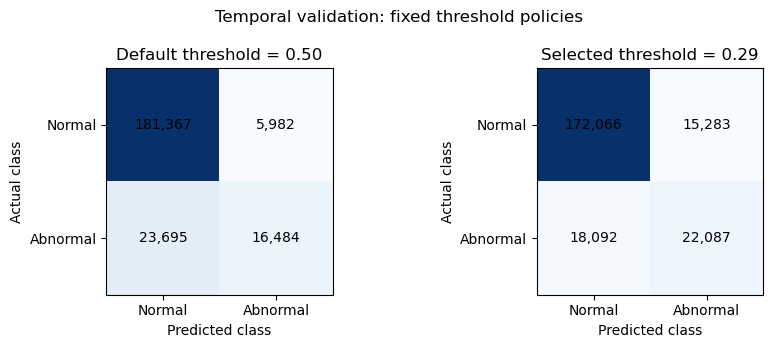

,Policy,Threshold,Sessions,Abnormal prevalence,Precision,Recall,F1,Balanced accuracy,Accuracy,TP,FP,FN,TN,Alert rate (%),Correct alerts / 1000,False alerts / 1000,Missed abnormalities / 1000,Mean fold F1,SD fold F1
0,Default,0.50,227528,0.1766,0.7337,0.4103,0.5263,0.6892,0.8696,16484,5982,23695,181367,9.8739,72.4482,26.2913,104.1410,0.5156,0.0477
1,Selected,0.29,227528,0.1766,0.5910,0.5497,0.5696,0.7341,0.8533,22087,15283,18092,172066,16.4244,97.0738,67.1698,79.5155,0.5614,0.0379


In [96]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for axis, (policy, threshold) in zip(
    axes, [("Default", 0.50), ("Selected", selected_threshold)]
):
    matrix = confusion_matrix(
        validation_actual, validation_scores >= threshold, labels=[0, 1]
    )
    axis.imshow(matrix, cmap="Blues")
    for row in range(2):
        for column in range(2):
            axis.text(column, row, f"{matrix[row, column]:,}",
                      ha="center", va="center")
    axis.set_xticks([0, 1], ["Normal", "Abnormal"])
    axis.set_yticks([0, 1], ["Normal", "Abnormal"])
    axis.set_xlabel("Predicted class")
    axis.set_ylabel("Actual class")
    axis.set_title(f"{policy} threshold = {threshold:.2f}")
fig.suptitle("Temporal validation: fixed threshold policies")
plt.tight_layout()
plt.savefig("task4_validation_confusion_matrices.png", dpi=160)
plt.show()
display(validation_policy_summary.round(4))

### 4.7 Descriptive model interpretation

We interpret the selected boosting configuration using grouping, summary statistics and plots. For each original predictor, we describe how the model's score and alert rate vary across observed values or intervals. This analyses the model's own predictions, rather than just associations between predictors and the target.

Each validation score comes from the selected configuration trained only on earlier completed sessions. Numerical predictors with more than ten distinct values are divided into at most five quantile intervals; missing values form a separate category. Other predictors retain their observed categories. These are descriptive display choices, not tuned model parameters. We report all G4 predictors in a table and plot four predefined examples representing calendar, tariff, post history and user history. Per-fold tables show whether patterns persist over time.

These profiles are appropriate for describing the behaviour of a nonlinear model without assuming linear coefficients. They do not isolate a variable's contribution: correlated attributes and interactions can explain an observed pattern, and a flat marginal profile can hide an interaction. They are not a feature-importance ranking, a causal analysis or a replacement for a controlled ablation. The Task 3 ablation supplies separate evidence about information groups under a fixed decision-tree model, rather than the selected boosting model.

#### Prediction profile calculation

In [97]:
def describe_prediction_profiles(features, scores, threshold, folds=None):
    if len(features) != len(scores):
        raise ValueError("Features and scores must describe the same sessions")
    tables = []
    fold_tables = []
    for feature in features.columns:
        values = features[feature]
        if pd.api.types.is_numeric_dtype(values) and values.nunique() > 10:
            groups = pd.qcut(values, q=5, duplicates="drop")
            groups = groups.map(lambda interval: f"({interval.left:.3g}, {interval.right:.3g}]", na_action="ignore")
        else:
            groups = values
        frame = pd.DataFrame({
            "Value or interval": groups.astype("string").fillna("Missing").to_numpy(),
            "Score": np.asarray(scores),
            "Alert": np.asarray(scores) >= threshold
        })
        if isinstance(groups.dtype, pd.CategoricalDtype):
            ordered_labels = list(groups.cat.categories.astype(str))
        else:
            ordered_labels = [str(value) for value in sorted(values.dropna().unique())]
        if "Missing" not in ordered_labels:
            ordered_labels.append("Missing")
        frame["Value or interval"] = pd.Categorical(
            frame["Value or interval"], categories=ordered_labels, ordered=True
        )
        summary = frame.groupby("Value or interval", sort=True, observed=True).agg(
            Sessions=("Score", "size"),
            Mean_score=("Score", "mean"),
            Median_score=("Score", "median"),
            Alert_rate=("Alert", "mean")
        ).reset_index()
        summary.insert(0, "Feature", feature)
        tables.append(summary)
        if folds is not None:
            frame["Fold"] = np.asarray(folds)
            by_fold = frame.groupby(["Fold", "Value or interval"], sort=True, observed=True).agg(
                Sessions=("Score", "size"),
                Mean_score=("Score", "mean"),
                Alert_rate=("Alert", "mean")
            ).reset_index()
            by_fold.insert(0, "Feature", feature)
            fold_tables.append(by_fold)
    return (pd.concat(tables, ignore_index=True),
            pd.concat(fold_tables, ignore_index=True) if fold_tables else pd.DataFrame())

#### Temporal validation profiles

In [98]:
profile_examples = [
    "start_hour", "electricity_price",
    "post_previous_abnormal_rate_30D", "user_previous_abnormal_rate_730D"
]
validation_profile_features = X_train.loc[validation_actual.index, g4_features]
validation_profile_folds = np.concatenate([
    np.full(len(fold["Actual"]), fold["Fold"])
    for fold in final_validation_predictions
])
validation_profiles, validation_profiles_by_fold = describe_prediction_profiles(
    validation_profile_features, validation_scores, selected_threshold,
    folds=validation_profile_folds
)
validation_profiles.to_csv("task4_validation_prediction_profiles.csv", index=False)
validation_profiles_by_fold.to_csv("task4_validation_prediction_profiles_by_fold.csv", index=False)
display(validation_profiles.loc[
    validation_profiles["Feature"].isin(profile_examples)
].round(4))

,Feature,Value or interval,Sessions,Mean_score,Median_score,Alert_rate
16,start_hour,"(-0.001, 10]",49231,0.1647,0.0887,0.1508
17,start_hour,"(10, 13]",48084,0.1998,0.1132,0.1982
18,start_hour,"(13, 16]",46868,0.1894,0.1037,0.1791
19,start_hour,"(16, 20]",48398,0.1666,0.0890,0.1479
20,start_hour,"(20, 23]",34947,0.1578,0.0800,0.1392
48,electricity_price,0.3784,79127,0.1784,0.0966,0.1692
49,electricity_price,0.9014,123447,0.1791,0.0975,0.1666
50,electricity_price,1.2064,24954,0.1582,0.0811,0.1368
96,post_previous_abnormal_rate_30D,"(0.00285, 0.0523]",45532,0.0471,0.0315,0.0177
97,post_previous_abnormal_rate_30D,"(0.0523, 0.0955]",45482,0.0752,0.0506,0.0363


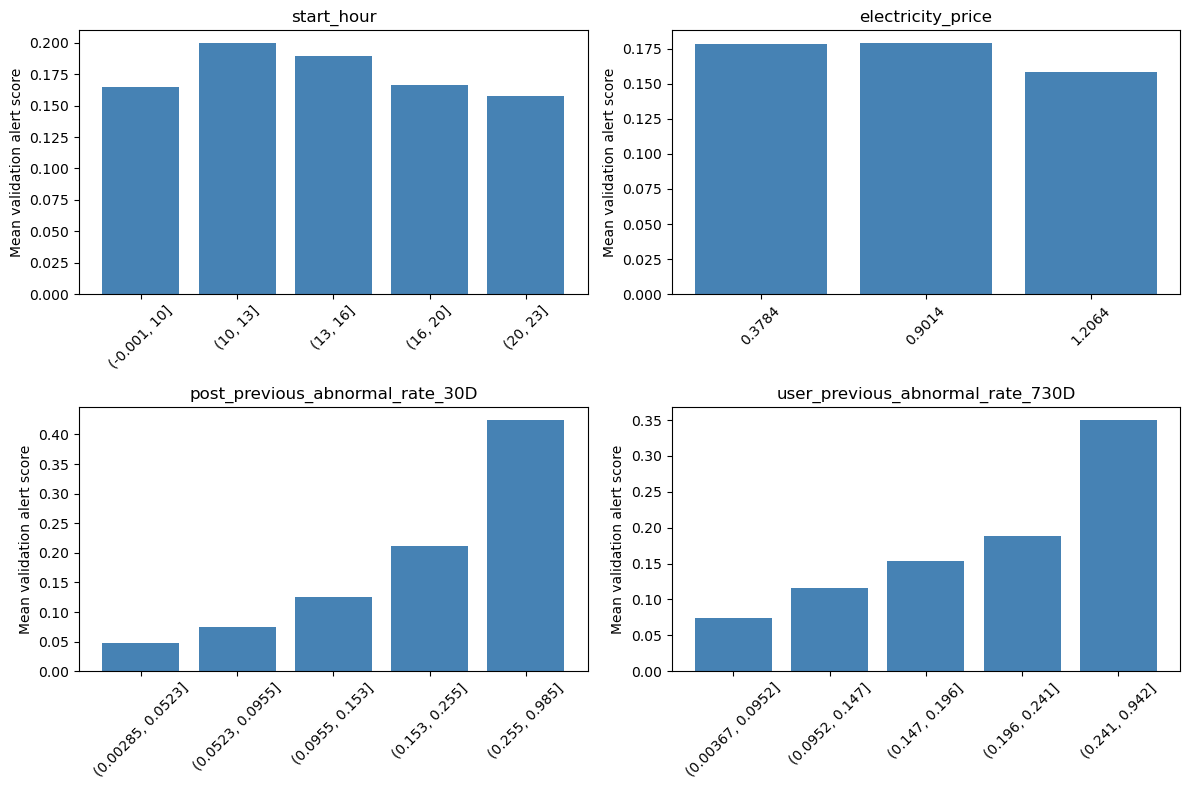

In [99]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for axis, feature in zip(axes.flat, profile_examples):
    profile = validation_profiles.loc[validation_profiles["Feature"] == feature]
    axis.bar(profile["Value or interval"], profile["Mean_score"], color="steelblue")
    axis.set_title(feature)
    axis.set_ylabel("Mean validation alert score")
    axis.tick_params(axis="x", labelrotation=45)
plt.tight_layout()
plt.savefig("task4_validation_prediction_profiles.png", dpi=160)
plt.show()

### 4.8 Fixed final model specification

The following cell displays the selected model, G4 predictors, preparation, hyperparameters, threshold and calibration policy before test prediction. The primary test policy uses the selected threshold unchanged; 0.50 is a prespecified comparison only. The model is refitted on all 294,006 development sessions completed before the cutoff, including eligible July sessions unused as a complete validation quarter. The 45 sessions still active at the cutoff are excluded.

The initial EDA inspected the eventual test period. This remains a limitation: the final period is protected from model-selection experiments but cannot be described as completely unseen.


In [100]:
classifier_parameters = final_model_template.named_steps["classifier"].get_params()

print("Selected model:", final_model_name)
print("Final training sessions:", len(X_final_train))
print("Final threshold:", selected_threshold)
display(pd.DataFrame([classifier_parameters]))


Selected model: Histogram Gradient Boosting
Final training sessions: 294006
Final threshold: 0.29


,categorical_features,class_weight,early_stopping,interaction_cst,l2_regularization,learning_rate,loss,max_bins,max_depth,max_features,...,max_leaf_nodes,min_samples_leaf,monotonic_cst,n_iter_no_change,random_state,scoring,tol,validation_fraction,verbose,warm_start
0,from_dtype,None,False,None,0.0,0.05,log_loss,255,None,1.0,...,31,50,None,10,42,loss,1.000000e-07,0.1,0,False


### 4.9 Final test evaluation

The fixed pipeline is fitted on eligible development data and generates test scores once within the execution. The fitted model and its predictions remain in memory for the subsequent analyses. Both reported thresholds were specified before testing; threshold 0.29 is the primary policy and 0.50 is the reference.

The evaluation includes overall metrics, operational consequences, monthly stability and history subgroups at the same fixed threshold. July is a partial month. These diagnostics describe the selected solution without subgroup-specific tuning.

#### Final model fitting and test predictions


In [101]:
final_model = clone(final_model_template)
with threadpool_limits(limits=2):
    begin = perf_counter()
    final_model.fit(X_final_train[g4_features], y_final_train)
    final_training_seconds = perf_counter() - begin

    begin = perf_counter()
    positive_column = np.flatnonzero(final_model.classes_ == 1).item()
    test_probabilities = final_model.predict_proba(
        X_test[g4_features]
    )[:, positive_column]
    final_prediction_seconds = perf_counter() - begin

if not np.isfinite(test_probabilities).all():
    raise ValueError("Invalid final-test scores")


#### Overall final test results

In [102]:
final_test_metrics = pd.DataFrame([
    {"Policy": policy, **evaluate_alert_policy(y_test, test_probabilities, threshold)}
    for policy, threshold in [("Default", 0.50), ("Selected", selected_threshold)]
])
print("Final test: Selected is the primary frozen policy; Default is a fixed comparison")
display(final_test_metrics.round(4))
print("Final fit time:", round(final_training_seconds, 2), "seconds")
print("Final prediction time:", round(final_prediction_seconds, 2), "seconds")
final_test_metrics.to_csv("task4_final_test_metrics.csv", index=False)

Final test: Selected is the primary frozen policy; Default is a fixed comparison


,Policy,Threshold,Sessions,Abnormal prevalence,Precision,Recall,F1,Balanced accuracy,Accuracy,TP,FP,FN,TN,Alert rate (%),Correct alerts / 1000,False alerts / 1000,Missed abnormalities / 1000
0,Default,0.50,147026,0.1931,0.7146,0.3575,0.4766,0.6617,0.8483,10151,4054,18243,114578,9.6616,69.0422,27.5734,124.0801
1,Selected,0.29,147026,0.1931,0.5456,0.5359,0.5407,0.7146,0.8242,15217,12672,13177,105960,18.9688,103.4987,86.1888,89.6236


Final fit time: 15.38 seconds
Final prediction time: 2.63 seconds


#### Monthly final test results

In [103]:
test_months = start_time.loc[y_test.index].dt.to_period("M")
monthly_records = []
for month in sorted(test_months.unique()):
    mask = (test_months == month).to_numpy()
    monthly_records.append({
        "Month": str(month), "Partial month": str(month) == str(split_date.to_period("M")),
        **evaluate_alert_policy(y_test.to_numpy()[mask],
                                test_probabilities[mask], selected_threshold)
    })
final_test_monthly = pd.DataFrame(monthly_records)
print("Monthly performance at the frozen selected threshold")
display(final_test_monthly.round(4))
final_test_monthly.to_csv("task4_final_test_monthly.csv", index=False)

Monthly performance at the frozen selected threshold


,Month,Partial month,Threshold,Sessions,Abnormal prevalence,Precision,Recall,F1,Balanced accuracy,Accuracy,TP,FP,FN,TN,Alert rate (%),Correct alerts / 1000,False alerts / 1000,Missed abnormalities / 1000
0,2021-07,True,0.29,15879,0.1967,0.5915,0.5911,0.5913,0.7456,0.8393,1846,1275,1277,11481,19.6549,116.2542,80.2947,80.4207
1,2021-08,False,0.29,23692,0.2076,0.5862,0.5765,0.5813,0.7349,0.8276,2836,2002,2083,16771,20.4204,119.7029,84.5011,87.9200
2,2021-09,False,0.29,27374,0.2288,0.5671,0.6349,0.5991,0.7455,0.8055,3977,3036,2287,18074,25.6192,145.2838,110.9082,83.5464
3,2021-10,False,0.29,27794,0.1860,0.5086,0.4867,0.4974,0.6896,0.8170,2516,2431,2654,20193,17.7988,90.5231,87.4649,95.4882
4,2021-11,False,0.29,25669,0.1650,0.4852,0.4190,0.4497,0.6656,0.8308,1775,1883,2461,19550,14.2507,69.1496,73.3570,95.8744
5,2021-12,False,0.29,26618,0.1759,0.5257,0.4842,0.5041,0.6955,0.8324,2267,2045,2415,19891,16.1996,85.1679,76.8277,90.7281


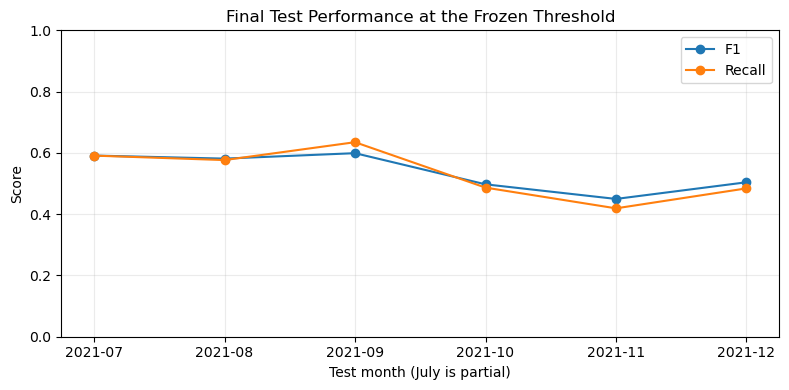

In [104]:
plt.figure(figsize=(8, 4))
plt.plot(final_test_monthly["Month"], final_test_monthly["F1"], marker="o", label="F1")
plt.plot(final_test_monthly["Month"], final_test_monthly["Recall"], marker="o", label="Recall")
plt.ylim(0, 1)
plt.ylabel("Score")
plt.xlabel("Test month (July is partial)")
plt.title("Final Test Performance at the Frozen Threshold")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig("task4_final_test_monthly.png", dpi=160)
plt.show()

#### Final results by history availability

In [105]:
history_test_records = []
history_flags = df.loc[y_test.index, [
    "user_no_previous_completed_session", "post_no_previous_completed_session"
]]
for subgroup, mask in [
    ("No completed user history", history_flags["user_no_previous_completed_session"].to_numpy() == 1),
    ("Has completed user history", history_flags["user_no_previous_completed_session"].to_numpy() == 0),
    ("No completed post history", history_flags["post_no_previous_completed_session"].to_numpy() == 1)
]:
    if mask.sum():
        history_test_records.append({"Subgroup": subgroup, **evaluate_alert_policy(
            y_test.to_numpy()[mask], test_probabilities[mask], selected_threshold
        )})
    else:
        history_test_records.append({"Subgroup": subgroup, "Sessions": 0,
                                     "F1": np.nan, "Recall": np.nan})
final_test_history = pd.DataFrame(history_test_records)
print("Final-test history subgroups; empty groups have undefined metrics")
display(final_test_history.round(4))
final_test_history.to_csv("task4_final_test_history.csv", index=False)

Final-test history subgroups; empty groups have undefined metrics


,Subgroup,Threshold,Sessions,Abnormal prevalence,Precision,Recall,F1,Balanced accuracy,Accuracy,TP,FP,FN,TN,Alert rate (%),Correct alerts / 1000,False alerts / 1000,Missed abnormalities / 1000
0,No completed user history,0.29,18893,0.2100,0.4875,0.4169,0.4495,0.6502,0.7855,1654.0,1739.0,2313.0,13187.0,17.9590,87.5457,92.0447,122.4263
1,Has completed user history,0.29,128133,0.1906,0.5537,0.5552,0.5545,0.7249,0.8299,13563.0,10933.0,10864.0,92773.0,19.1176,105.8510,85.3254,84.7869
2,No completed post history,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


#### Final test baselines

In [106]:
training_majority = int(y_final_train.mode().iloc[0])
final_test_baselines = pd.DataFrame([
    {"Baseline": name, **evaluate_alert_policy(
        y_test, np.full(len(y_test), float(predicted_class)), 0.50
    )}
    for name, predicted_class in [
        ("Training majority", training_majority), ("Always abnormal", 1)
    ]
])
print("Prespecified simple baselines on the same final test sessions")
display(final_test_baselines.round(4))
final_test_baselines.to_csv("task4_final_test_baselines.csv", index=False)

Prespecified simple baselines on the same final test sessions


,Baseline,Threshold,Sessions,Abnormal prevalence,Precision,Recall,F1,Balanced accuracy,Accuracy,TP,FP,FN,TN,Alert rate (%),Correct alerts / 1000,False alerts / 1000,Missed abnormalities / 1000
0,Training majority,0.5,147026,0.1931,0.0000,0.0,0.0000,0.5,0.8069,0,0,28394,118632,0.0,0.0000,0.0000,193.1223
1,Always abnormal,0.5,147026,0.1931,0.1931,1.0,0.3237,0.5,0.1931,28394,118632,0,0,100.0,193.1223,806.8777,0.0000


### 4.10 Profiles of the final fitted pipeline

We apply the same grouping analysis to the final fitted pipeline on all eligible development sessions. It uses the pipeline fitted during the current execution, without refitting and without accessing final-test outcomes. We show mean scores and alert rates by observed predictor values, including sessions without completed user history.

This describes the particular model retained for operation, while the earlier profiles describe the selected configuration across temporal validation fits. Development-data profiles can be optimistic and are not a new generalisation estimate. Differences across groups cannot be attributed to one predictor alone because other attributes also differ. These limitations prevent a causal or independent feature-importance interpretation.

In [107]:
with threadpool_limits(limits=2):
    final_development_scores = final_model.predict_proba(
        X_final_train[g4_features]
    )[:, np.flatnonzero(final_model.classes_ == 1).item()]
final_prediction_profiles, _ = describe_prediction_profiles(
    X_final_train[g4_features], final_development_scores, selected_threshold
)
final_prediction_profiles.to_csv("task4_final_prediction_profiles.csv", index=False)
final_profile_examples = profile_examples + ["user_no_previous_completed_session"]
display(final_prediction_profiles.loc[
    final_prediction_profiles["Feature"].isin(final_profile_examples)
].round(4))
print("Descriptive development-data profiles; no refitting or test-based decisions")

,Feature,Value or interval,Sessions,Mean_score,Median_score,Alert_rate
16,start_hour,"(-0.001, 10]",63450,0.1738,0.1062,0.1578
17,start_hour,"(10, 13]",61775,0.2021,0.1266,0.2002
18,start_hour,"(13, 16]",61296,0.1927,0.1146,0.1819
19,start_hour,"(16, 20]",62396,0.1740,0.1032,0.1522
20,start_hour,"(20, 23]",45089,0.1633,0.0929,0.1414
48,electricity_price,0.3784,101970,0.1835,0.1110,0.1726
49,electricity_price,0.9014,159761,0.1844,0.1108,0.1705
50,electricity_price,1.2064,32275,0.1666,0.0952,0.1414
96,post_previous_abnormal_rate_30D,"(0.00285, 0.0585]",58808,0.0450,0.0271,0.0205
97,post_previous_abnormal_rate_30D,"(0.0585, 0.106]",58801,0.0861,0.0606,0.0457


Descriptive development-data profiles; no refitting or test-based decisions


### 4.11 Final results and limitations

The frozen Histogram Gradient Boosting model uses G4, 150 iterations, learning rate 0.05, at most 31 leaves per tree and minimum leaf size 50. At the unchanged threshold **0.29**, final-test F1 is **0.5407**, precision **0.5456** and recall **0.5359** on **147,026** later sessions. The selected policy produces **15,217 TP**, **12,672 FP**, **13,177 FN** and **105,960 TN**.

Compared with the prespecified default threshold, F1 rises from 0.4766 to 0.5407 and recall from 0.3575 to 0.5359, while precision falls from 0.7146 to 0.5456. Alerts rise from 9.66% to 18.97% of sessions. Per 1,000 sessions, the selected policy yields 103.50 correct alerts, 86.19 false alerts and 89.62 missed abnormalities. It detects 34.46 additional abnormalities but produces 58.62 additional false alerts per 1,000 relative to 0.50. Acceptability depends on monitoring capacity and action costs, which are unknown.

Final pooled F1 (0.5407) is below pooled validation F1 (0.5696); the primary development mean-fold F1 was 0.5614 and is a different aggregation. Monthly test F1 ranges from 0.4497 to 0.5991. Recall without completed user history is 0.4169, compared with 0.5552 when that history is available. These differences indicate temporal variation and lower detection in sessions without user history. There are no new-post cases to assess.

Prediction profiles describe how the selected model's scores and alert rates vary with observed calendar, tariff and historical attributes. Temporal validation profiles and development-data profiles of the final fitted pipeline are reported separately. Correlated attributes prevent attributing these associations to independent effects, and these descriptive results do not establish causality or a model-specific ranking of group importance. The fixed-tree ablation from Task 3 remains separate evidence about the predictive usefulness of information groups. For example, across temporal validation predictions, the lowest observed quintile of the post abnormal-rate history has mean score 0.0471 and alert rate 1.77%, versus mean score 0.4246 and alert rate 50.49% in the highest quintile. For user abnormal-rate history, the corresponding mean scores are 0.0746 and 0.3503, with alert rates 4.01% and 48.37%. These patterns are consistent with higher alert scores in sessions with worse historical outcomes, without isolating history from the other inputs. Mean scores across the three electricity-price levels range from 0.1582 to 0.1791; this smaller marginal contrast does not prove a negligible tariff contribution.

The threshold and model were frozen before test prediction and were not changed afterward. Earlier descriptive inspection of the eventual test period, reuse of development outcomes, limited search spaces, correlated histories, uncertain absolute-risk calibration and absent external-network evaluation remain limitations.